# GINE + CNN Additional Experiment

This notebook introduces a bond-aware GINE drug encoder while retaining the existing protein CNN.

The experiment begins with the Davis random split.

GINE will only be evaluated on the remaining Davis and KIBA splits if its Davis random-split validation performance is competitive with the existing models.

The experiment uses the same:

- processed dataset;
- random split;
- protein CNN;
- hidden dimensions;
- optimiser;
- batch size;
- early stopping;
- random seed;
- regression metrics.

The only intended architectural difference is the use of molecular bond features in the GINE drug encoder.

# Project setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

import config as cfg

print("Project root:", PROJECT_ROOT)
print("PyTorch version:", torch.__version__)

try:
    import torch_geometric

    print(
        "PyTorch Geometric version:",
        torch_geometric.__version__,
    )

except ImportError as error:
    raise ImportError(
        "PyTorch Geometric is not available "
        "in the current environment."
    ) from error

Project root: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing
PyTorch version: 2.13.0
PyTorch Geometric version: 2.8.0.post1


In [2]:
import importlib
import src.preprocessing as preprocessing

# importlib.reload(preprocessing)

# print("preprocessing.py reloaded")

# Define relevant paths

In [3]:
SRC_DIR = PROJECT_ROOT / "src"

PREPROCESSING_FILE = (
    SRC_DIR / "preprocessing.py"
)

DATASET_FILE = (
    SRC_DIR / "dataset.py"
)

MODELS_FILE = (
    SRC_DIR / "models.py"
)

DAVIS_PAIRS_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "davis_pairs.csv"
)

DAVIS_RANDOM_SPLIT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "splits"
    / "random"
)

print("Preprocessing file:")
print(PREPROCESSING_FILE)

print("\nDataset file:")
print(DATASET_FILE)

print("\nModels file:")
print(MODELS_FILE)

print("\nDavis random split directory:")
print(DAVIS_RANDOM_SPLIT_DIR)

Preprocessing file:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/src/preprocessing.py

Dataset file:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/src/dataset.py

Models file:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/src/models.py

Davis random split directory:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/splits/random


# Confirm required files

In [4]:
required_project_files = [
    PREPROCESSING_FILE,
    DATASET_FILE,
    MODELS_FILE,
]

for file_path in required_project_files:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in required_project_files
)

print("\nRequired source files found.")

preprocessing.py → True
dataset.py → True
models.py → True

Required source files found.


# Inspect the current drug graph
## Import the current preprocessing function

In [5]:
from src.preprocessing import (
    build_drug_graph_cache,
)

print(
    "Current drug graph cache function imported."
)

Current drug graph cache function imported.


# Load a small Davis sample

In [6]:
assert DAVIS_PAIRS_PATH.exists(), (
    f"Missing Davis processed file: "
    f"{DAVIS_PAIRS_PATH}"
)

davis_pairs_df = pd.read_csv(
    DAVIS_PAIRS_PATH
)

print(
    "Davis processed shape:",
    davis_pairs_df.shape,
)

print(
    "Davis columns:",
    davis_pairs_df.columns.tolist(),
)

display(
    davis_pairs_df.head()
)

Davis processed shape: (30056, 8)
Davis columns: ['dataset', 'drug_id', 'target_id', 'smiles', 'protein_sequence', 'raw_affinity', 'affinity', 'affinity_type']


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type
0,davis,11314340,AAK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,43.0,7.366532,pKd
1,davis,11314340,ABL1(E255K),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
2,davis,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
3,davis,11314340,ABL1(F317I)p,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
4,davis,11314340,ABL1(F317L),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd


# Build a small graph cache

In [7]:
davis_graph_test_df = (
    davis_pairs_df
    .drop_duplicates(
        subset="drug_id"
    )
    .head(3)
    .copy()
)

davis_graph_test_cache = (
    build_drug_graph_cache(
        davis_graph_test_df
    )
)

print(
    "Test drug graphs created:",
    len(davis_graph_test_cache),
)

Test drug graphs created: 3


# Inspect every graph attribute

In [8]:
example_drug_id = next(
    iter(davis_graph_test_cache)
)

example_drug_graph = (
    davis_graph_test_cache[
        example_drug_id
    ]
)

print("Example drug ID:", example_drug_id)
print()
print(example_drug_graph)

print("\nGraph keys:")
print(
    list(
        example_drug_graph.keys()
    )
)

print("\nNode features:")
print(example_drug_graph.x.shape)

print("\nEdge index:")
print(example_drug_graph.edge_index.shape)

print("\nHas edge_attr:")
print(
    hasattr(
        example_drug_graph,
        "edge_attr",
    )
)

if (
    hasattr(
        example_drug_graph,
        "edge_attr",
    )
    and example_drug_graph.edge_attr
    is not None
):
    print("\nEdge attributes:")
    print(
        example_drug_graph.edge_attr.shape
    )

    print("\nFirst five edge attributes:")
    print(
        example_drug_graph.edge_attr[:5]
    )

else:
    print(
        "\nCurrent molecular graphs do not "
        "contain bond features."
    )

Example drug ID: 11314340

Data(x=[27, 6], edge_index=[2, 60], edge_attr=[60, 6], num_nodes=27)

Graph keys:
['edge_index', 'num_nodes', 'edge_attr', 'x']

Node features:
torch.Size([27, 6])

Edge index:
torch.Size([2, 60])

Has edge_attr:
True

Edge attributes:
torch.Size([60, 6])

First five edge attributes:
tensor([[1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.]])


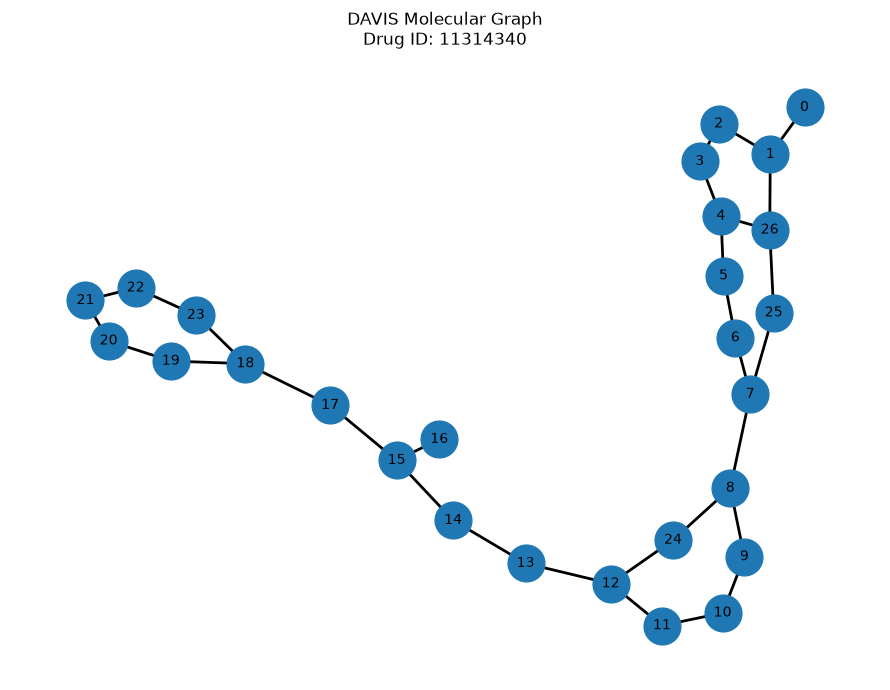

Drug ID: 11314340
Number of atoms: 27
Number of directed edges: 60
Approximate number of bonds: 30


In [9]:
# ============================================================
# Visualise one DAVIS molecular graph
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx


# ------------------------------------------------------------
# 1. Convert PyTorch Geometric graph to NetworkX
# ------------------------------------------------------------

graph_nx = nx.Graph()

num_nodes = example_drug_graph.x.size(0)

# Add atoms / nodes
graph_nx.add_nodes_from(
    range(num_nodes)
)


# ------------------------------------------------------------
# 2. Add bonds / edges
# ------------------------------------------------------------

edge_index = (
    example_drug_graph
    .edge_index
    .detach()
    .cpu()
    .numpy()
)

for source, target in edge_index.T:
    graph_nx.add_edge(
        int(source),
        int(target),
    )


# ------------------------------------------------------------
# 3. Generate node positions
# ------------------------------------------------------------

positions = nx.spring_layout(
    graph_nx,
    seed=42,
)


# ------------------------------------------------------------
# 4. Draw molecular graph
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 7)
)

nx.draw_networkx_nodes(
    graph_nx,
    positions,
    node_size=700,
)

nx.draw_networkx_edges(
    graph_nx,
    positions,
    width=2,
)

nx.draw_networkx_labels(
    graph_nx,
    positions,
    font_size=10,
)


plt.title(
    f"DAVIS Molecular Graph\nDrug ID: {example_drug_id}"
)

plt.axis("off")

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 5. Print graph information
# ------------------------------------------------------------

print(
    "Drug ID:",
    example_drug_id,
)

print(
    "Number of atoms:",
    example_drug_graph.num_nodes,
)

print(
    "Number of directed edges:",
    example_drug_graph.edge_index.shape[1],
)

print(
    "Approximate number of bonds:",
    example_drug_graph.edge_index.shape[1] // 2,
)

# Validate graph edge alignment

In [10]:
number_of_directed_edges = (
    example_drug_graph
    .edge_index
    .shape[1]
)

print(
    "Directed graph edges:",
    number_of_directed_edges,
)

if (
    hasattr(
        example_drug_graph,
        "edge_attr",
    )
    and example_drug_graph.edge_attr
    is not None
):
    number_of_edge_feature_rows = (
        example_drug_graph
        .edge_attr
        .shape[0]
    )

    print(
        "Edge-feature rows:",
        number_of_edge_feature_rows,
    )

    assert (
        number_of_directed_edges
        == number_of_edge_feature_rows
    )

    print(
        "Edge index and edge attributes "
        "are aligned."
    )

else:
    print(
        "Bond features must be added before "
        "GINE can be implemented."
    )

Directed graph edges: 60
Edge-feature rows: 60
Edge index and edge attributes are aligned.


1. single bond
2. double bond
3. triple bond
4. aromatic bond
5. conjugated bond
6. bond is in a ring

# Verify bond-feature graphs

In [11]:
# ============================================================
# Check DAVIS graph edge attributes
# ============================================================

print("Number of cached drugs:", len(davis_graph_test_cache))

for drug_id, graph in list(
    davis_graph_test_cache.items()
)[:5]:

    print("\nDrug ID:", drug_id)

    print(
        "Node features:",
        graph.x.shape,
    )

    print(
        "Edge index:",
        graph.edge_index.shape,
    )

    print(
        "Has edge_attr attribute:",
        hasattr(graph, "edge_attr"),
    )

    if hasattr(graph, "edge_attr"):
        print(
            "edge_attr:",
            graph.edge_attr,
        )

Number of cached drugs: 3

Drug ID: 11314340
Node features: torch.Size([27, 6])
Edge index: torch.Size([2, 60])
Has edge_attr attribute: True
edge_attr: tensor([[1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [1., 0., 0., 0., 1., 0.],
        [1., 0., 0., 0., 1., 0.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [1., 0., 0., 0., 1., 0.

In [12]:
# ============================================================
# Find molecular graph functions in preprocessing.py
# ============================================================

import inspect
import src.preprocessing as preprocessing


for name, obj in inspect.getmembers(
    preprocessing,
    inspect.isfunction,
):
    if (
        "graph" in name.lower()
        or "smile" in name.lower()
        or "molecule" in name.lower()
    ):
        print("\n" + "=" * 70)
        print("FUNCTION:", name)
        print("=" * 70)

        try:
            print(inspect.getsource(obj))
        except Exception as error:
            print(
                "Could not display source:",
                error,
            )


FUNCTION: build_drug_graph_cache
def build_drug_graph_cache(
    dataframe: pd.DataFrame,
    drug_id_column: str = "drug_id",
    smiles_column: str = "smiles",
) -> Dict[str, Data]:
    """Create one molecular graph for every unique drug."""

    _check_unique_mapping(
        dataframe,
        drug_id_column,
        smiles_column,
    )

    unique_drugs = dataframe[
        [drug_id_column, smiles_column]
    ].drop_duplicates(subset=[drug_id_column])

    graph_cache: Dict[str, Data] = {}

    for row in unique_drugs.itertuples(index=False):
        drug_id = str(getattr(row, drug_id_column))
        smiles = getattr(row, smiles_column)

        graph_cache[drug_id] = smiles_to_graph(smiles)

    return graph_cache


FUNCTION: canonicalize_smiles
def canonicalize_smiles(smiles: str) -> str:
    """Convert a SMILES string into its canonical RDKit representation."""

    if not isinstance(smiles, str) or not smiles.strip():
        raise ValueError("SMILES must be a non-empty str

In [13]:
import inspect
import src.preprocessing as preprocessing

print(
    inspect.getsource(
        preprocessing.bond_to_feature_vector
    )
)

def bond_to_feature_vector(
    bond,
) -> list[float]:
    """Convert one RDKit bond into six features."""

    bond_type = bond.GetBondType()

    return [
        float(
            bond_type
            == Chem.rdchem.BondType.SINGLE
        ),
        float(
            bond_type
            == Chem.rdchem.BondType.DOUBLE
        ),
        float(
            bond_type
            == Chem.rdchem.BondType.TRIPLE
        ),
        float(
            bond_type
            == Chem.rdchem.BondType.AROMATIC
        ),
        float(
            bond.GetIsConjugated()
        ),
        float(
            bond.IsInRing()
        ),
    ]



In [14]:
# ============================================================
# STEP 1 — Check whether the NEW graph builder works
# ============================================================

import importlib
import src.preprocessing as preprocessing

importlib.reload(preprocessing)

test_graph = preprocessing.smiles_to_graph(
    "CCO"
)

print(test_graph)

print("\nx shape:")
print(test_graph.x.shape)

print("\nedge_index shape:")
print(test_graph.edge_index.shape)

print("\nedge_attr:")
print(test_graph.edge_attr)

print("\nedge_attr shape:")
print(
    None
    if test_graph.edge_attr is None
    else test_graph.edge_attr.shape
)

Data(x=[3, 6], edge_index=[2, 4], edge_attr=[4, 6], num_nodes=3)

x shape:
torch.Size([3, 6])

edge_index shape:
torch.Size([2, 4])

edge_attr:
tensor([[1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.]])

edge_attr shape:
torch.Size([4, 6])


In [15]:
test_smiles = "CCO"

test_graph = (
    preprocessing.smiles_to_graph(
        test_smiles
    )
)

print(test_graph)

print("\nNode features:")
print(test_graph.x.shape)

print("\nEdge index:")
print(test_graph.edge_index.shape)

print("\nEdge attributes:")
print(test_graph.edge_attr.shape)

print("\nEdge attributes:")
print(test_graph.edge_attr)

Data(x=[3, 6], edge_index=[2, 4], edge_attr=[4, 6], num_nodes=3)

Node features:
torch.Size([3, 6])

Edge index:
torch.Size([2, 4])

Edge attributes:
torch.Size([4, 6])

Edge attributes:
tensor([[1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.]])


In [16]:
import src.preprocessing as preprocessing

test_graph = preprocessing.smiles_to_graph("CCO")

print(test_graph)
print("x:", test_graph.x.shape)
print("edge_index:", test_graph.edge_index.shape)
print("edge_attr:", test_graph.edge_attr)
print(
    "edge_attr shape:",
    None if test_graph.edge_attr is None
    else test_graph.edge_attr.shape
)

Data(x=[3, 6], edge_index=[2, 4], edge_attr=[4, 6], num_nodes=3)
x: torch.Size([3, 6])
edge_index: torch.Size([2, 4])
edge_attr: tensor([[1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.]])
edge_attr shape: torch.Size([4, 6])


In [17]:
# ============================================================
# Check EXACT preprocessing.py code Jupyter is using
# ============================================================

import inspect
import src.preprocessing as preprocessing

print("FILE BEING USED:")
print(preprocessing.__file__)

print("\n" + "=" * 70)
print("CURRENT smiles_to_graph FUNCTION")
print("=" * 70)

print(
    inspect.getsource(
        preprocessing.smiles_to_graph
    )
)

FILE BEING USED:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/src/preprocessing.py

CURRENT smiles_to_graph FUNCTION
def smiles_to_graph(smiles: str) -> Data:
    """
    Convert a SMILES string into a PyTorch Geometric molecular graph.

    Each chemical bond is represented in both directions.

    Returns:
        Data object containing:
            x         -> atom features
            edge_index -> graph connectivity
            edge_attr  -> bond features
    """

    canonical_smiles = canonicalize_smiles(smiles)

    molecule = Chem.MolFromSmiles(
        canonical_smiles
    )

    if (
        molecule is None
        or molecule.GetNumAtoms() == 0
    ):
        raise ValueError(
            f"Unable to create molecule from SMILES: {smiles}"
        )

    # ========================================================
    # Node / atom features
    # =====================================================

In [18]:
import inspect
import src.preprocessing as preprocessing

print("FILE BEING USED:")
print(preprocessing.__file__)

print("\nCURRENT smiles_to_graph FUNCTION:\n")

print(
    inspect.getsource(
        preprocessing.smiles_to_graph
    )
)

FILE BEING USED:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/src/preprocessing.py

CURRENT smiles_to_graph FUNCTION:

def smiles_to_graph(smiles: str) -> Data:
    """
    Convert a SMILES string into a PyTorch Geometric molecular graph.

    Each chemical bond is represented in both directions.

    Returns:
        Data object containing:
            x         -> atom features
            edge_index -> graph connectivity
            edge_attr  -> bond features
    """

    canonical_smiles = canonicalize_smiles(smiles)

    molecule = Chem.MolFromSmiles(
        canonical_smiles
    )

    if (
        molecule is None
        or molecule.GetNumAtoms() == 0
    ):
        raise ValueError(
            f"Unable to create molecule from SMILES: {smiles}"
        )

    # ========================================================
    # Node / atom features
    # ===================================================

In [19]:
from src.preprocessing import (
    build_drug_graph_cache,
)

davis_graph_test_cache = (
    build_drug_graph_cache(
        davis_graph_test_df
    )
)

for drug_id, graph in (
    davis_graph_test_cache.items()
):
    assert graph.x.ndim == 2

    assert graph.edge_index.ndim == 2

    assert graph.edge_index.shape[0] == 2

    assert hasattr(
        graph,
        "edge_attr",
    )

    assert graph.edge_attr is not None

    assert graph.edge_attr.ndim == 2

    assert (
        graph.edge_attr.shape[0]
        == graph.edge_index.shape[1]
    )

    assert (
        graph.edge_attr.shape[1]
        == cfg.BOND_FEATURE_DIM
    )

    assert torch.isfinite(
        graph.edge_attr
    ).all()

print(
    "All test graphs contain valid "
    "bond features."
)

All test graphs contain valid bond features.


# Check the dataset preserves edge_attr — Inspect DTADataset

In [20]:
from src.dataset import DTADataset
from src.preprocessing import (
    build_protein_tensor_cache,
)

davis_dataset_test_df = (
    davis_pairs_df.head(8).copy()
)

davis_dataset_drug_cache = (
    build_drug_graph_cache(
        davis_dataset_test_df
    )
)

davis_dataset_protein_cache = (
    build_protein_tensor_cache(
        davis_dataset_test_df
    )
)

davis_dataset_test = DTADataset(
    davis_dataset_test_df,
    davis_dataset_drug_cache,
    davis_dataset_protein_cache,
)

davis_dataset_sample = (
    davis_dataset_test[0]
)

print(davis_dataset_sample)

print(
    "Sample edge attributes:",
    davis_dataset_sample.edge_attr.shape,
)

assert hasattr(
    davis_dataset_sample,
    "edge_attr",
)

assert (
    davis_dataset_sample.edge_attr.shape[0]
    == davis_dataset_sample.edge_index.shape[1]
)

print(
    "DTADataset preserves bond features."
)

Data(x=[27, 6], edge_index=[2, 60], edge_attr=[60, 6], num_nodes=27, target=[1, 1000], sample_id=[1], y=[1])
Sample edge attributes: torch.Size([60, 6])
DTADataset preserves bond features.


# Inspect your existing model structure first

In [21]:
import inspect
import src.models as models_module

print("Classes/functions inside src.models:")
print()

for name, object_value in vars(
    models_module
).items():

    if (
        inspect.isclass(object_value)
        or inspect.isfunction(object_value)
    ):
        if getattr(
            object_value,
            "__module__",
            None,
        ) == models_module.__name__:

            print(name)

Classes/functions inside src.models:

DrugGCNEncoder
DrugGATEncoder
_create_gin_mlp
DrugGINEncoder
GINEDrugEncoder
ProteinCNNEncoder
DTAModel
create_dta_model


# Inspect the existing GIN encoder

In [22]:
gin_class_candidates = [
    name
    for name in dir(models_module)
    if "GIN" in name.upper()
    and "GINE" not in name.upper()
]

print(
    "GIN-related classes:",
    gin_class_candidates,
)

for class_name in gin_class_candidates:
    object_value = getattr(
        models_module,
        class_name,
    )

    if inspect.isclass(object_value):
        print()
        print("=" * 70)
        print(class_name)
        print("=" * 70)

        print(
            inspect.getsource(
                object_value
            )
        )

GIN-related classes: ['GINConv', '_create_gin_mlp']

GINConv
class GINConv(MessagePassing):
    r"""The graph isomorphism operator from the `"How Powerful are
    Graph Neural Networks?" <https://arxiv.org/abs/1810.00826>`_ paper.

    .. math::
        \mathbf{x}^{\prime}_i = h_{\mathbf{\Theta}} \left( (1 + \epsilon) \cdot
        \mathbf{x}_i + \sum_{j \in \mathcal{N}(i)} \mathbf{x}_j \right)

    or

    .. math::
        \mathbf{X}^{\prime} = h_{\mathbf{\Theta}} \left( \left( \mathbf{A} +
        (1 + \epsilon) \cdot \mathbf{I} \right) \cdot \mathbf{X} \right),

    here :math:`h_{\mathbf{\Theta}}` denotes a neural network, *.i.e.* an MLP.

    Args:
        nn (torch.nn.Module): A neural network :math:`h_{\mathbf{\Theta}}` that
            maps node features :obj:`x` of shape :obj:`[-1, in_channels]` to
            shape :obj:`[-1, out_channels]`, *e.g.*, defined by
            :class:`torch.nn.Sequential`.
        eps (float, optional): (Initial) :math:`\epsilon`-value.
         

In [23]:
from src.models import (
    GINEDrugEncoder,
    create_dta_model,
)

print(
    "GINEDrugEncoder imported successfully."
)

print(
    "Bond feature dimension:",
    cfg.BOND_FEATURE_DIM,
)

GINEDrugEncoder imported successfully.
Bond feature dimension: 6


In [24]:
import torch
import torch_geometric
from rdkit import Chem

print("Torch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("MPS:", torch.backends.mps.is_available())

Torch: 2.13.0
PyG: 2.8.0.post1
MPS: True


In [25]:
from src.preprocessing import smiles_to_graph

test_graph = smiles_to_graph("CCO")

print(test_graph)
print("edge_attr:", test_graph.edge_attr)
print("edge_attr shape:", test_graph.edge_attr.shape)

Data(x=[3, 6], edge_index=[2, 4], edge_attr=[4, 6], num_nodes=3)
edge_attr: tensor([[1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.]])
edge_attr shape: torch.Size([4, 6])


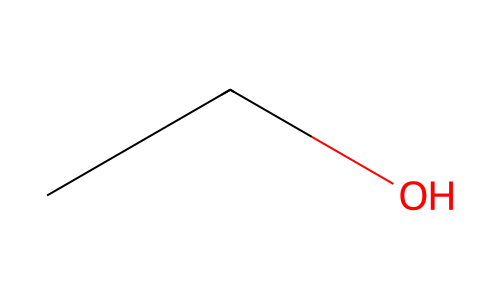

In [26]:
from rdkit import Chem
from rdkit.Chem import Draw

# Same molecule used for test_graph
smiles = "CCO"

mol = Chem.MolFromSmiles(smiles)

Draw.MolToImage(
    mol,
    size=(500, 300),
)

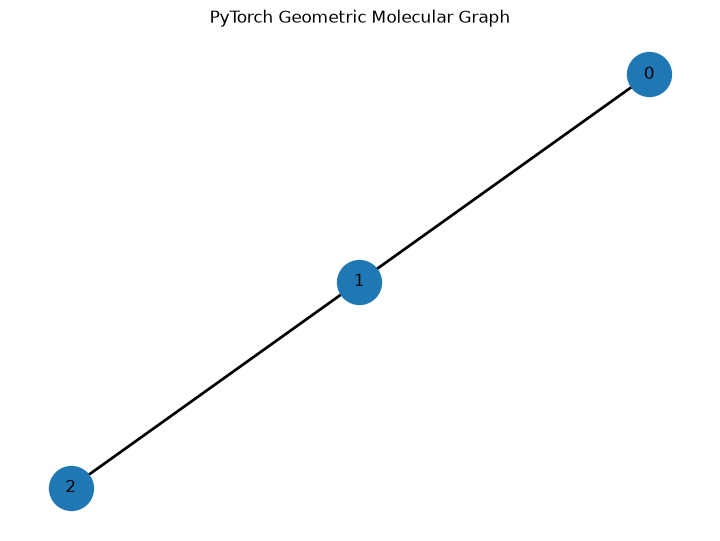

In [27]:
import matplotlib.pyplot as plt
import networkx as nx

# Create NetworkX graph
G = nx.Graph()

# Add nodes
for node_id in range(test_graph.num_nodes):
    G.add_node(node_id)

# Get edges
edge_index = (
    test_graph.edge_index
    .detach()
    .cpu()
    .numpy()
)

# Add edges
for source, target in edge_index.T:
    G.add_edge(
        int(source),
        int(target),
    )

# Layout
pos = nx.spring_layout(
    G,
    seed=42,
)

# Draw
plt.figure(figsize=(7, 5))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1000,
    font_size=12,
    width=2,
)

plt.title("PyTorch Geometric Molecular Graph")

plt.show()

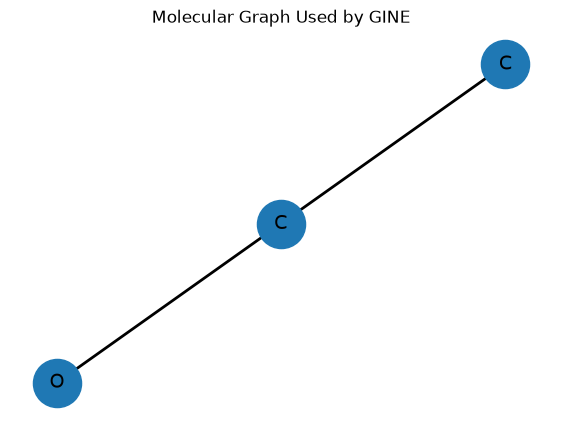

In [28]:
import matplotlib.pyplot as plt
import networkx as nx
from rdkit import Chem


smiles = "CCO"

mol = Chem.MolFromSmiles(smiles)

G = nx.Graph()

# ------------------------------------------------------------
# Add atoms
# ------------------------------------------------------------

for atom in mol.GetAtoms():

    atom_index = atom.GetIdx()
    atom_symbol = atom.GetSymbol()

    G.add_node(
        atom_index,
        label=atom_symbol,
    )


# ------------------------------------------------------------
# Add bonds
# ------------------------------------------------------------

edge_index = (
    test_graph.edge_index
    .detach()
    .cpu()
    .numpy()
)

for source, target in edge_index.T:

    G.add_edge(
        int(source),
        int(target),
    )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

labels = {
    node: G.nodes[node]["label"]
    for node in G.nodes
}


# ------------------------------------------------------------
# Draw
# ------------------------------------------------------------

pos = nx.spring_layout(
    G,
    seed=42,
)

plt.figure(
    figsize=(7, 5)
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=1200,
)

nx.draw_networkx_edges(
    G,
    pos,
    width=2,
)

nx.draw_networkx_labels(
    G,
    pos,
    labels=labels,
    font_size=14,
)

plt.title(
    "Molecular Graph Used by GINE"
)

plt.axis("off")
plt.show()

# Confirm GINE exists

In [29]:
from src.models import (
    GINEDrugEncoder,
    create_dta_model,
)

print(
    "GINEDrugEncoder imported successfully."
)

print(
    "Bond feature dimension:",
    cfg.BOND_FEATURE_DIM,
)

GINEDrugEncoder imported successfully.
Bond feature dimension: 6


# Create a fresh GINE + CNN model

In [30]:
from src.utils import (
    get_device,
    set_random_seed,
)

set_random_seed(
    cfg.RANDOM_SEED
)

device = get_device()

gine_test_model = (
    create_dta_model(
        model_name="gine"
    )
    .to(device)
)

print(gine_test_model)

print()
print(
    "Device:",
    device,
)

DTAModel(
  (drug_encoder): GINEDrugEncoder(
    (conv1): GINEConv(nn=Sequential(
      (0): Linear(in_features=6, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
    ))
    (norm1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): GINEConv(nn=Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
    ))
    (norm2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv3): GINEConv(nn=Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
    ))
    (norm3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (protein_encoder): ProteinCNNEncoder(
    (embedding): Embedding(2

# Count GINE parameters

In [31]:
gine_trainable_parameters = sum(
    parameter.numel()
    for parameter in (
        gine_test_model.parameters()
    )
    if parameter.requires_grad
)

print(
    "GINE + CNN trainable parameters:",
    f"{gine_trainable_parameters:,}",
)

GINE + CNN trainable parameters: 351,403


# Build a small Davis test batch

In [32]:
from torch_geometric.loader import (
    DataLoader,
)

davis_gine_test_loader = DataLoader(
    davis_dataset_test,
    batch_size=4,
    shuffle=False,
)

davis_gine_test_batch = next(
    iter(
        davis_gine_test_loader
    )
)

print(davis_gine_test_batch)

print()
print(
    "Node features:",
    davis_gine_test_batch.x.shape,
)

print(
    "Edge index:",
    davis_gine_test_batch.edge_index.shape,
)

print(
    "Edge attributes:",
    davis_gine_test_batch.edge_attr.shape,
)

print(
    "Protein:",
    davis_gine_test_batch.target.shape,
)

print(
    "Graphs:",
    davis_gine_test_batch.num_graphs,
)

assert (
    davis_gine_test_batch.edge_attr.shape[0]
    == davis_gine_test_batch.edge_index.shape[1]
)

assert (
    davis_gine_test_batch.edge_attr.shape[1]
    == cfg.BOND_FEATURE_DIM
)

DataBatch(x=[108, 6], edge_index=[2, 240], edge_attr=[240, 6], num_nodes=108, target=[4, 1000], sample_id=[4], y=[4], batch=[108], ptr=[5])

Node features: torch.Size([108, 6])
Edge index: torch.Size([2, 240])
Edge attributes: torch.Size([240, 6])
Protein: torch.Size([4, 1000])
Graphs: 4


# Run the first GINE + CNN forward pass

In [33]:
gine_test_model.eval()

davis_gine_test_batch = (
    davis_gine_test_batch.to(
        device
    )
)

with torch.no_grad():

    gine_test_predictions = (
        gine_test_model(
            davis_gine_test_batch
        )
        .view(-1)
    )

print(
    "Prediction shape:",
    gine_test_predictions.shape,
)

print(
    "Predictions:"
)

print(
    gine_test_predictions
)

assert (
    gine_test_predictions.shape[0]
    == davis_gine_test_batch.num_graphs
)

assert torch.isfinite(
    gine_test_predictions
).all()

print()
print(
    "GINE + CNN forward pass successful."
)

Prediction shape: torch.Size([4])
Predictions:
tensor([0.1381, 0.1184, 0.1184, 0.1184], device='mps:0')

GINE + CNN forward pass successful.


# Check gradients

In [34]:
gine_test_model.train()

davis_gine_test_batch = next(
    iter(
        davis_gine_test_loader
    )
).to(device)

gine_test_model.zero_grad()

gine_training_predictions = (
    gine_test_model(
        davis_gine_test_batch
    )
    .view(-1)
)

gine_training_targets = (
    davis_gine_test_batch.y
    .view(-1)
    .float()
)

gine_test_loss = (
    torch.nn.functional.mse_loss(
        gine_training_predictions,
        gine_training_targets,
    )
)

gine_test_loss.backward()

gradient_parameter_count = sum(
    1
    for parameter
    in gine_test_model.parameters()
    if (
        parameter.grad is not None
        and torch.isfinite(
            parameter.grad
        ).all()
    )
)

print(
    "Test loss:",
    float(
        gine_test_loss.detach().cpu()
    ),
)

print(
    "Parameters with valid gradients:",
    gradient_parameter_count,
)

assert gradient_parameter_count > 0

print()
print(
    "GINE + CNN backward pass successful."
)

Test loss: 29.522096633911133
Parameters with valid gradients: 33

GINE + CNN backward pass successful.


# Confirm GINE actually uses bond features

In [35]:
import copy

gine_test_model.eval()

original_batch = next(
    iter(
        davis_gine_test_loader
    )
).to(device)

modified_batch = copy.deepcopy(
    original_batch
)

modified_batch.edge_attr = (
    torch.zeros_like(
        modified_batch.edge_attr
    )
)

with torch.no_grad():

    original_predictions = (
        gine_test_model(
            original_batch
        )
        .view(-1)
    )

    zero_bond_predictions = (
        gine_test_model(
            modified_batch
        )
        .view(-1)
    )

prediction_difference = (
    torch.abs(
        original_predictions
        - zero_bond_predictions
    )
    .mean()
)

print(
    "Mean prediction difference after "
    "removing bond information:",
    float(
        prediction_difference.cpu()
    ),
)

assert (
    prediction_difference.item()
    > 0
)

print()
print(
    "GINE is responding to bond features."
)

Mean prediction difference after removing bond information: 0.006258390843868256

GINE is responding to bond features.


# Make sure old models still work

In [36]:
existing_model_names = [
    "gcn",
    "gat",
    "gin",
]

compatibility_results = []

test_batch = next(
    iter(
        davis_gine_test_loader
    )
).to(device)

for model_name in existing_model_names:

    set_random_seed(
        cfg.RANDOM_SEED
    )

    model = (
        create_dta_model(
            model_name=model_name
        )
        .to(device)
    )

    model.eval()

    with torch.no_grad():

        predictions = (
            model(
                test_batch
            )
            .view(-1)
        )

    compatibility_results.append(
        {
            "model": model_name,
            "prediction_count": int(
                predictions.shape[0]
            ),
            "all_finite": bool(
                torch.isfinite(
                    predictions
                ).all()
            ),
        }
    )

compatibility_results_df = (
    pd.DataFrame(
        compatibility_results
    )
)

display(
    compatibility_results_df
)

assert (
    compatibility_results_df[
        "all_finite"
    ].all()
)

print(
    "GCN, GAT and GIN remain compatible "
    "after adding edge attributes."
)

,model,prediction_count,all_finite
0,gcn,4,True
1,gat,4,True
2,gin,4,True


GCN, GAT and GIN remain compatible after adding edge attributes.


# Final architecture check

In [38]:
gine_architecture_check = {

    "drug_encoder": "GINE",

    "protein_encoder": "CNN",

    "node_feature_dim": int(
        cfg.NODE_FEATURE_DIM
    ),

    "bond_feature_dim": int(
        cfg.BOND_FEATURE_DIM
    ),

    "hidden_dim": int(
        cfg.DRUG_HIDDEN_DIM
    ),

    "dropout": float(
        cfg.DROPOUT
    ),

    "trainable_parameters": int(
        gine_trainable_parameters
    ),

    "forward_pass": True,

    "backward_pass": True,

    "bond_features_used": True,

    "existing_models_compatible": True,
}


print(
    "GINE + CNN architecture check"
)

print()

for key, value in (
    gine_architecture_check.items()
):

    print(
        f"{key}: {value}"
    )

GINE + CNN architecture check

drug_encoder: GINE
protein_encoder: CNN
node_feature_dim: 6
bond_feature_dim: 6
hidden_dim: 128
dropout: 0.2
trainable_parameters: 351403
forward_pass: True
backward_pass: True
bond_features_used: True
existing_models_compatible: True


## GINE + CNN Architecture Successfully Added

The project now supports four molecular graph encoders:

- GCN + CNN
- GAT + CNN
- GIN + CNN
- GINE + CNN

Unlike the original graph encoders, GINE explicitly incorporates molecular bond features during message passing.

The GINE implementation was verified by:

- confirming edge attributes are present;
- verifying edge and bond-feature alignment;
- running a successful forward pass;
- running a successful backward pass;
- confirming predictions respond to bond features;
- confirming the existing GCN, GAT and GIN models remain operational.

The next experiment trains GINE + CNN on the Davis random split using the same training configuration and split used for the previous baseline models.

# Davis Random Split — GINE + CNN

The GINE + CNN architecture is now evaluated on the existing Davis random split.

For a fair comparison, this experiment uses the same:

- training, validation and test samples;
- protein CNN;
- hidden dimensions;
- batch size;
- optimiser;
- learning rate;
- number of epochs;
- early stopping;
- random seed.

The main model-selection criterion is validation MSE.

Test RMSE, MAE, CI and Pearson correlation are reported after loading the best validation checkpoint.

# Imports

In [39]:
import gc
import json
import time

import numpy as np
import pandas as pd
import torch

from torch_geometric.loader import DataLoader

from src.preprocessing import (
    build_drug_graph_cache,
    build_protein_tensor_cache,
)

from src.dataset import DTADataset

from src.models import (
    create_dta_model,
)

from src.training import (
    fit_model,
    load_checkpoint,
)

from src.utils import (
    get_device,
    set_random_seed,
)

print("Training imports successful.")

Training imports successful.


# Read the actual training configuration

In [40]:
GINE_RANDOM_SEED = int(
    getattr(
        cfg,
        "RANDOM_SEED",
        42,
    )
)

GINE_BATCH_SIZE = int(
    getattr(
        cfg,
        "BATCH_SIZE",
        32,
    )
)

GINE_NUM_EPOCHS = int(
    getattr(
        cfg,
        "NUM_EPOCHS",
        getattr(
            cfg,
            "EPOCHS",
            30,
        ),
    )
)

GINE_LEARNING_RATE = float(
    getattr(
        cfg,
        "LEARNING_RATE",
        1e-3,
    )
)

GINE_WEIGHT_DECAY = float(
    getattr(
        cfg,
        "WEIGHT_DECAY",
        1e-5,
    )
)

GINE_PATIENCE = int(
    getattr(
        cfg,
        "PATIENCE",
        7,
    )
)

GINE_NUM_WORKERS = int(
    getattr(
        cfg,
        "NUM_WORKERS",
        0,
    )
)

GINE_PIN_MEMORY = bool(
    getattr(
        cfg,
        "PIN_MEMORY",
        False,
    )
)

print(
    "Random seed:",
    GINE_RANDOM_SEED,
)

print(
    "Batch size:",
    GINE_BATCH_SIZE,
)

print(
    "Epochs:",
    GINE_NUM_EPOCHS,
)

print(
    "Learning rate:",
    GINE_LEARNING_RATE,
)

print(
    "Weight decay:",
    GINE_WEIGHT_DECAY,
)

print(
    "Patience:",
    GINE_PATIENCE,
)

print(
    "Workers:",
    GINE_NUM_WORKERS,
)

Random seed: 42
Batch size: 32
Epochs: 30
Learning rate: 0.001
Weight decay: 1e-05
Patience: 7
Workers: 0


# Load exactly the same Davis random split

In [43]:
DAVIS_RANDOM_SPLIT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "splits"
    / "random"
)

davis_random_train_path = (
    DAVIS_RANDOM_SPLIT_DIR
    / "davis_train.csv"
)

davis_random_validation_path = (
    DAVIS_RANDOM_SPLIT_DIR
    / "davis_validation.csv"
)

davis_random_test_path = (
    DAVIS_RANDOM_SPLIT_DIR
    / "davis_test.csv"
)

random_split_paths = [
    davis_random_train_path,
    davis_random_validation_path,
    davis_random_test_path,
]

for file_path in random_split_paths:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in random_split_paths
)

print(
    "\nDavis random split files found."
)

davis_train.csv → True
davis_validation.csv → True
davis_test.csv → True

Davis random split files found.


In [42]:
from pathlib import Path

print("PROJECT_ROOT:")
print(PROJECT_ROOT)

print("\nExpected split directory:")
print(DAVIS_RANDOM_SPLIT_DIR)

print("\nDirectory exists:")
print(DAVIS_RANDOM_SPLIT_DIR.exists())

print("\nExpected files:")

for file_path in random_split_paths:
    print(
        file_path,
        "→",
        file_path.exists(),
    )

print("\nActual files under processed/splits:")

splits_root = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "splits"
)

if splits_root.exists():

    for path in sorted(
        splits_root.rglob("*")
    ):
        if path.is_file():
            print(
                path.relative_to(
                    PROJECT_ROOT
                )
            )

else:
    print(
        "Splits directory does not exist."
    )

PROJECT_ROOT:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing

Expected split directory:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/splits/random

Directory exists:
True

Expected files:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/splits/random/davis_train.csv → True
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/splits/random/davis_val.csv → False
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/splits/random/davis_test.csv → True

Actual files under processed/splits:
data/processed/splits/cold_drug/.gitkeep
data/processed/splits/cold_drug/davis_test.csv

# Load the split tables

In [44]:
davis_gine_train_df = pd.read_csv(
    davis_random_train_path
)

davis_gine_validation_df = pd.read_csv(
    davis_random_validation_path
)

davis_gine_test_df = pd.read_csv(
    davis_random_test_path
)

print(
    "Train:",
    davis_gine_train_df.shape,
)

print(
    "Validation:",
    davis_gine_validation_df.shape,
)

print(
    "Test:",
    davis_gine_test_df.shape,
)

print()

print(
    "Columns:",
    davis_gine_train_df.columns.tolist(),
)

Train: (21039, 8)
Validation: (4508, 8)
Test: (4509, 8)

Columns: ['dataset', 'drug_id', 'target_id', 'smiles', 'protein_sequence', 'raw_affinity', 'affinity', 'affinity_type']


# Confirm split consistency

In [45]:
assert (
    davis_gine_train_df.columns.tolist()
    == davis_gine_validation_df.columns.tolist()
)

assert (
    davis_gine_train_df.columns.tolist()
    == davis_gine_test_df.columns.tolist()
)

assert not davis_gine_train_df.empty
assert not davis_gine_validation_df.empty
assert not davis_gine_test_df.empty

print(
    "Davis random splits validated."
)

Davis random splits validated.


# Build bond-aware graph caches

In [46]:
davis_gine_all_df = pd.concat(
    [
        davis_gine_train_df,
        davis_gine_validation_df,
        davis_gine_test_df,
    ],
    ignore_index=True,
)

print(
    "Combined Davis rows:",
    len(davis_gine_all_df),
)

print(
    "Unique drugs:",
    davis_gine_all_df[
        "drug_id"
    ].nunique(),
)

print(
    "Unique targets:",
    davis_gine_all_df[
        "target_id"
    ].nunique(),
)

Combined Davis rows: 30056
Unique drugs: 68
Unique targets: 442


# Build the drug graph cache

In [47]:
davis_gine_drug_graph_cache = (
    build_drug_graph_cache(
        davis_gine_all_df
    )
)

print(
    "Cached Davis drugs:",
    len(
        davis_gine_drug_graph_cache
    ),
)

example_gine_drug_id = next(
    iter(
        davis_gine_drug_graph_cache
    )
)

example_gine_graph = (
    davis_gine_drug_graph_cache[
        example_gine_drug_id
    ]
)

print()

print(
    "Node features:",
    example_gine_graph.x.shape,
)

print(
    "Edges:",
    example_gine_graph.edge_index.shape,
)

print(
    "Bond features:",
    example_gine_graph.edge_attr.shape,
)

assert (
    example_gine_graph.edge_attr.shape[0]
    == example_gine_graph.edge_index.shape[1]
)

assert (
    example_gine_graph.edge_attr.shape[1]
    == cfg.BOND_FEATURE_DIM
)

print(
    "\nBond-aware Davis graph cache validated."
)

Cached Davis drugs: 68

Node features: torch.Size([32, 6])
Edges: torch.Size([2, 70])
Bond features: torch.Size([70, 6])

Bond-aware Davis graph cache validated.


# Build the protein cache

In [48]:
davis_gine_protein_tensor_cache = (
    build_protein_tensor_cache(
        davis_gine_all_df
    )
)

print(
    "Cached Davis targets:",
    len(
        davis_gine_protein_tensor_cache
    ),
)

assert (
    len(
        davis_gine_protein_tensor_cache
    )
    == davis_gine_all_df[
        "target_id"
    ].nunique()
)

print(
    "Davis protein cache validated."
)

Cached Davis targets: 442
Davis protein cache validated.


# Create train, validation and test datasets

In [49]:
davis_gine_train_dataset = DTADataset(
    davis_gine_train_df,
    davis_gine_drug_graph_cache,
    davis_gine_protein_tensor_cache,
)

davis_gine_validation_dataset = DTADataset(
    davis_gine_validation_df,
    davis_gine_drug_graph_cache,
    davis_gine_protein_tensor_cache,
)

davis_gine_test_dataset = DTADataset(
    davis_gine_test_df,
    davis_gine_drug_graph_cache,
    davis_gine_protein_tensor_cache,
)

print(
    "Train samples:",
    len(
        davis_gine_train_dataset
    ),
)

print(
    "Validation samples:",
    len(
        davis_gine_validation_dataset
    ),
)

print(
    "Test samples:",
    len(
        davis_gine_test_dataset
    ),
)

assert (
    len(davis_gine_train_dataset)
    == len(davis_gine_train_df)
)

assert (
    len(davis_gine_validation_dataset)
    == len(davis_gine_validation_df)
)

assert (
    len(davis_gine_test_dataset)
    == len(davis_gine_test_df)
)

Train samples: 21039
Validation samples: 4508
Test samples: 4509


# Create DataLoaders

In [50]:
davis_gine_train_loader = DataLoader(
    davis_gine_train_dataset,
    batch_size=GINE_BATCH_SIZE,
    shuffle=True,
    num_workers=GINE_NUM_WORKERS,
    pin_memory=GINE_PIN_MEMORY,
)

davis_gine_validation_loader = DataLoader(
    davis_gine_validation_dataset,
    batch_size=GINE_BATCH_SIZE,
    shuffle=False,
    num_workers=GINE_NUM_WORKERS,
    pin_memory=GINE_PIN_MEMORY,
)

davis_gine_test_loader = DataLoader(
    davis_gine_test_dataset,
    batch_size=GINE_BATCH_SIZE,
    shuffle=False,
    num_workers=GINE_NUM_WORKERS,
    pin_memory=GINE_PIN_MEMORY,
)

print(
    "Train batches:",
    len(
        davis_gine_train_loader
    ),
)

print(
    "Validation batches:",
    len(
        davis_gine_validation_loader
    ),
)

print(
    "Test batches:",
    len(
        davis_gine_test_loader
    ),
)

Train batches: 658
Validation batches: 141
Test batches: 141


# Check one training batch

In [51]:
davis_gine_training_batch = next(
    iter(
        davis_gine_train_loader
    )
)

print(
    "Graphs:",
    davis_gine_training_batch.num_graphs,
)

print(
    "Node features:",
    davis_gine_training_batch.x.shape,
)

print(
    "Edge index:",
    davis_gine_training_batch.edge_index.shape,
)

print(
    "Edge attributes:",
    davis_gine_training_batch.edge_attr.shape,
)

print(
    "Protein:",
    davis_gine_training_batch.target.shape,
)

print(
    "Affinity:",
    davis_gine_training_batch.y.shape,
)

assert (
    davis_gine_training_batch.edge_attr.shape[0]
    == davis_gine_training_batch.edge_index.shape[1]
)

assert (
    davis_gine_training_batch.edge_attr.shape[1]
    == cfg.BOND_FEATURE_DIM
)

print(
    "\nDavis GINE training batch validated."
)

Graphs: 32
Node features: torch.Size([1054, 6])
Edge index: torch.Size([2, 2342])
Edge attributes: torch.Size([2342, 6])
Protein: torch.Size([32, 1000])
Affinity: torch.Size([32])

Davis GINE training batch validated.


# Create GINE + CNN

In [52]:
set_random_seed(
    GINE_RANDOM_SEED
)

device = get_device()

davis_gine_random_model = (
    create_dta_model(
        model_name="gine"
    )
    .to(device)
)

davis_gine_random_parameter_count = sum(
    parameter.numel()
    for parameter
    in davis_gine_random_model.parameters()
    if parameter.requires_grad
)

print(
    "Device:",
    device,
)

print(
    "Trainable parameters:",
    f"{davis_gine_random_parameter_count:,}",
)

Device: mps
Trainable parameters: 351,403


# Create optimizer and checkpoint path

In [53]:
davis_gine_random_optimizer = (
    torch.optim.Adam(
        davis_gine_random_model.parameters(),
        lr=GINE_LEARNING_RATE,
        weight_decay=(
            GINE_WEIGHT_DECAY
        ),
    )
)

davis_gine_random_checkpoint = (
    PROJECT_ROOT
    / "models"
    / "best_davis_gine_cnn_random.pt"
)

davis_gine_random_checkpoint.parent.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Checkpoint:",
    davis_gine_random_checkpoint,
)

print(
    "Optimizer:",
    davis_gine_random_optimizer.__class__.__name__,
)

Checkpoint: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gine_cnn_random.pt
Optimizer: Adam


# Train GINE + CNN

In [54]:
set_random_seed(
    GINE_RANDOM_SEED
)

gine_training_start_time = (
    time.perf_counter()
)

davis_gine_random_result = fit_model(
    model=davis_gine_random_model,
    train_loader=(
        davis_gine_train_loader
    ),
    validation_loader=(
        davis_gine_validation_loader
    ),
    optimizer=(
        davis_gine_random_optimizer
    ),
    device=device,
    num_epochs=GINE_NUM_EPOCHS,
    checkpoint_path=(
        davis_gine_random_checkpoint
    ),
    patience=GINE_PATIENCE,
)

gine_training_runtime_seconds = (
    time.perf_counter()
    - gine_training_start_time
)

print()

print(
    "Training runtime:",
    round(
        gine_training_runtime_seconds,
        2,
    ),
    "seconds",
)

print(
    "Checkpoint exists:",
    davis_gine_random_checkpoint.exists(),
)

Epoch 001 | Train MSE: 1.0185 | Validation MSE: 0.6815 | RMSE: 0.8255 | MAE: 0.4950
Epoch 002 | Train MSE: 0.8216 | Validation MSE: 0.9086 | RMSE: 0.9532 | MAE: 0.6876
Epoch 003 | Train MSE: 0.7789 | Validation MSE: 0.5613 | RMSE: 0.7492 | MAE: 0.4844
Epoch 004 | Train MSE: 0.7606 | Validation MSE: 0.5562 | RMSE: 0.7458 | MAE: 0.4849
Epoch 005 | Train MSE: 0.7502 | Validation MSE: 0.5920 | RMSE: 0.7694 | MAE: 0.4685
Epoch 006 | Train MSE: 0.7315 | Validation MSE: 0.5647 | RMSE: 0.7515 | MAE: 0.4792
Epoch 007 | Train MSE: 0.7451 | Validation MSE: 0.5830 | RMSE: 0.7635 | MAE: 0.4769
Epoch 008 | Train MSE: 0.7132 | Validation MSE: 0.5308 | RMSE: 0.7285 | MAE: 0.4580
Epoch 009 | Train MSE: 0.7040 | Validation MSE: 0.5776 | RMSE: 0.7600 | MAE: 0.5026
Epoch 010 | Train MSE: 0.6978 | Validation MSE: 0.5812 | RMSE: 0.7624 | MAE: 0.4684
Epoch 011 | Train MSE: 0.6852 | Validation MSE: 0.5255 | RMSE: 0.7249 | MAE: 0.4381
Epoch 012 | Train MSE: 0.6789 | Validation MSE: 0.5520 | RMSE: 0.7430 | MAE:

# Inspect the training result safely

In [61]:
history = davis_gine_random_result.get(
    "history",
    {}
)

print("HISTORY TYPE:")
print(type(history))

print("\nHISTORY:")
print(history)

if isinstance(history, dict):
    print("\nHISTORY KEYS:")
    print(history.keys())

HISTORY TYPE:
<class 'dict'>

HISTORY:
{'epoch': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30], 'train_mse': [1.0184795887639435, 0.8216478144398965, 0.7789091437841142, 0.7605520217436462, 0.750154968733411, 0.7314558791436591, 0.7450750419478084, 0.7132480513704464, 0.7039942308885697, 0.6978000676321992, 0.6852044364156545, 0.6788634205647558, 0.6716558032063251, 0.6479515961987862, 0.645148199836906, 0.646961681360278, 0.6259591265563089, 0.6206065332980498, 0.6189203875458871, 0.6070487415520285, 0.6006747512282729, 0.6012613876086688, 0.5889190989328466, 0.5904403750949941, 0.5836126128016579, 0.5755630870543991, 0.573923144108658, 0.5739751707742471, 0.5631911458900953, 0.5545919397973794], 'validation_mse': [0.6815240959974858, 0.9086381269360896, 0.5613422362629937, 0.5562115252592036, 0.5919806191985554, 0.5647315793322036, 0.5829906462789071, 0.530761177409379, 0.5775892357114636, 0.5811943038090598, 0.5254530

In [56]:
print(
    "Result keys:",
    davis_gine_random_result.keys(),
)

print("\nBest epoch:")
print(
    davis_gine_random_result.get(
        "best_epoch"
    )
)

print("\nHistory length:")
print(
    len(
        davis_gine_random_result.get(
            "history",
            []
        )
    )
)

print("\nFirst history row:")
if davis_gine_random_result.get("history"):
    print(
        davis_gine_random_result[
            "history"
        ][0]
    )

print("\nLast history row:")
if davis_gine_random_result.get("history"):
    print(
        davis_gine_random_result[
            "history"
        ][-1]
    )
    

Result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])

Best epoch:
30

History length:
7

First history row:


KeyError: 0

In [62]:
history = davis_gine_random_result[
    "history"
]

validation_mse_values = history[
    "validation_mse"
]

epoch_values = history[
    "epoch"
]

best_index = min(
    range(len(validation_mse_values)),
    key=lambda i: validation_mse_values[i],
)

davis_gine_random_best_mse = (
    validation_mse_values[
        best_index
    ]
)

davis_gine_random_best_epoch = (
    epoch_values[
        best_index
    ]
)


print(
    "Best epoch:",
    davis_gine_random_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            davis_gine_random_best_mse
        ),
        4,
    ),
)

print(
    "Best validation RMSE:",
    round(
        float(
            history[
                "validation_rmse"
            ][best_index]
        ),
        4,
    ),
)

print(
    "Best validation MAE:",
    round(
        float(
            history[
                "validation_mae"
            ][best_index]
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(
        history[
            "epoch"
        ]
    ),
)

print(
    "Checkpoint exists:",
    davis_gine_random_checkpoint.exists(),
)

Best epoch: 30
Best validation MSE: 0.452
Best validation RMSE: 0.6723
Best validation MAE: 0.4208
Completed epochs: 30
Checkpoint exists: True


# Load the best checkpoint

In [63]:
load_checkpoint(
    model=davis_gine_random_model,
    checkpoint_path=(
        davis_gine_random_checkpoint
    ),
    device=device,
)

davis_gine_random_model.eval()

print(
    "Best Davis random GINE + CNN "
    "checkpoint loaded."
)

Best Davis random GINE + CNN checkpoint loaded.


# Define evaluation metrics

In [64]:
def calculate_concordance_index(
    true_values,
    predicted_values,
):
    true_values = np.asarray(
        true_values,
        dtype=float,
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float,
    )

    concordant = 0.0
    comparable = 0

    for i in range(
        len(true_values)
    ):
        for j in range(
            i + 1,
            len(true_values),
        ):
            if (
                true_values[i]
                == true_values[j]
            ):
                continue

            comparable += 1

            true_direction = (
                true_values[i]
                > true_values[j]
            )

            predicted_difference = (
                predicted_values[i]
                - predicted_values[j]
            )

            if predicted_difference == 0:
                concordant += 0.5

            elif (
                predicted_difference > 0
            ) == true_direction:
                concordant += 1.0

    if comparable == 0:
        return np.nan

    return (
        concordant
        / comparable
    )


def evaluate_gine_regression(
    model,
    data_loader,
    device,
):
    model.eval()

    true_values = []
    predicted_values = []

    with torch.no_grad():

        for batch in data_loader:

            batch = batch.to(
                device
            )

            predictions = (
                model(batch)
                .view(-1)
            )

            targets = (
                batch.y
                .view(-1)
                .float()
            )

            predicted_values.extend(
                predictions
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )

            true_values.extend(
                targets
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )

    true_values = np.asarray(
        true_values,
        dtype=float,
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float,
    )

    errors = (
        true_values
        - predicted_values
    )

    mse = float(
        np.mean(
            errors ** 2
        )
    )

    rmse = float(
        np.sqrt(mse)
    )

    mae = float(
        np.mean(
            np.abs(errors)
        )
    )

    ci = float(
        calculate_concordance_index(
            true_values,
            predicted_values,
        )
    )

    if (
        np.std(true_values) == 0
        or np.std(
            predicted_values
        ) == 0
    ):
        pearson = np.nan

    else:
        pearson = float(
            np.corrcoef(
                true_values,
                predicted_values,
            )[0, 1]
        )

    return {
        "mse": mse,
        "rmse": rmse,
        "mae": mae,
        "ci": ci,
        "pearson": pearson,
        "true_values": true_values,
        "predicted_values": (
            predicted_values
        ),
    }


print(
    "GINE regression evaluator created."
)

GINE regression evaluator created.


# Evaluate validation and test sets

In [65]:
davis_gine_validation_metrics = (
    evaluate_gine_regression(
        model=davis_gine_random_model,
        data_loader=(
            davis_gine_validation_loader
        ),
        device=device,
    )
)

davis_gine_test_metrics = (
    evaluate_gine_regression(
        model=davis_gine_random_model,
        data_loader=(
            davis_gine_test_loader
        ),
        device=device,
    )
)

print(
    "BEST VALIDATION MSE:",
    round(
        float(
            davis_gine_random_best_mse
        ),
        4,
    ),
)

print()

print("TEST RESULTS")

print(
    "MSE:",
    round(
        davis_gine_test_metrics[
            "mse"
        ],
        4,
    ),
)

print(
    "RMSE:",
    round(
        davis_gine_test_metrics[
            "rmse"
        ],
        4,
    ),
)

print(
    "MAE:",
    round(
        davis_gine_test_metrics[
            "mae"
        ],
        4,
    ),
)

print(
    "CI:",
    round(
        davis_gine_test_metrics[
            "ci"
        ],
        4,
    ),
)

print(
    "Pearson:",
    round(
        davis_gine_test_metrics[
            "pearson"
        ],
        4,
    ),
)

BEST VALIDATION MSE: 0.452

TEST RESULTS
MSE: 0.4749
RMSE: 0.6891
MAE: 0.4317
CI: 0.819
Pearson: 0.6303


# Compare against existing models

In [67]:
davis_random_model_comparison_df = (
    pd.DataFrame(
        [
            {
                "model": "GCN + CNN",
                "best_validation_mse": (
                    0.5633
                ),
                "test_rmse": 0.7789,
                "test_ci": 0.7562,
            },
            {
                "model": "GIN + CNN",
                "best_validation_mse": (
                    0.5568
                ),
                "test_rmse": 0.7745,
                "test_ci": 0.7494,
            },
            {
                "model": "GAT + CNN",
                "best_validation_mse": (
                    0.4851
                ),
                "test_rmse": 0.7141,
                "test_ci": 0.7963,
            },
            {
                "model": "GINE + CNN",
                "best_validation_mse": (
                    float(
                        davis_gine_random_best_mse
                    )
                ),
                "test_rmse": (
                    davis_gine_test_metrics[
                        "rmse"
                    ]
                ),
                "test_ci": (
                    davis_gine_test_metrics[
                        "ci"
                    ]
                ),
            },
        ]
    )
)

davis_random_model_comparison_df[
    "validation_rank"
] = (
    davis_random_model_comparison_df[
        "best_validation_mse"
    ]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)

davis_random_model_comparison_df = (
    davis_random_model_comparison_df
    .sort_values(
        "best_validation_mse"
    )
    .reset_index(drop=True)
)

display(
    davis_random_model_comparison_df.round(
        4
    )
)

,model,best_validation_mse,test_rmse,test_ci,validation_rank
0,GINE + CNN,0.4520,0.6891,0.8190,1
1,GAT + CNN,0.4851,0.7141,0.7963,2
2,GIN + CNN,0.5568,0.7745,0.7494,3
3,GCN + CNN,0.5633,0.7789,0.7562,4


# Apply our continuation rule

In [68]:
GAT_RANDOM_VALIDATION_MSE = 0.4851

GIN_RANDOM_VALIDATION_MSE = 0.5568

GINE_PROMISING_THRESHOLD = (
    GAT_RANDOM_VALIDATION_MSE
    * 1.02
)

gine_best_validation_mse = float(
    davis_gine_random_best_mse
)

if (
    gine_best_validation_mse
    < GAT_RANDOM_VALIDATION_MSE
):
    gine_decision = (
        "CONTINUE_ALL_SPLITS"
    )

    gine_decision_reason = (
        "GINE achieved a lower validation "
        "MSE than GAT + CNN."
    )

elif (
    gine_best_validation_mse
    <= GINE_PROMISING_THRESHOLD
):
    gine_decision = (
        "CONTINUE_ALL_SPLITS"
    )

    gine_decision_reason = (
        "GINE is within 2% of the best "
        "GAT validation MSE and is "
        "considered competitive."
    )

elif (
    gine_best_validation_mse
    < GIN_RANDOM_VALIDATION_MSE
):
    gine_decision = (
        "OPTIONAL_CONTINUE"
    )

    gine_decision_reason = (
        "GINE improves over GIN but is "
        "not competitive with GAT on "
        "Davis random validation."
    )

else:
    gine_decision = (
        "STOP_GINE_EXPANSION"
    )

    gine_decision_reason = (
        "GINE does not improve over the "
        "existing GIN baseline on Davis "
        "random validation."
    )

print(
    "GAT validation MSE:",
    GAT_RANDOM_VALIDATION_MSE,
)

print(
    "2% competitive threshold:",
    round(
        GINE_PROMISING_THRESHOLD,
        4,
    ),
)

print(
    "GIN validation MSE:",
    GIN_RANDOM_VALIDATION_MSE,
)

print()

print(
    "GINE validation MSE:",
    round(
        gine_best_validation_mse,
        4,
    ),
)

print()

print(
    "DECISION:",
    gine_decision,
)

print()

print(
    "REASON:",
    gine_decision_reason,
)

GAT validation MSE: 0.4851
2% competitive threshold: 0.4948
GIN validation MSE: 0.5568

GINE validation MSE: 0.452

DECISION: CONTINUE_ALL_SPLITS

REASON: GINE achieved a lower validation MSE than GAT + CNN.


# Save the GINE Davis-random experiment

In [69]:
GINE_METRICS_DIR = (
    PROJECT_ROOT
    / "results"
    / "metrics"
)

GINE_PREDICTIONS_DIR = (
    PROJECT_ROOT
    / "results"
    / "predictions"
)

GINE_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

GINE_PREDICTIONS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

davis_gine_random_metrics_path = (
    GINE_METRICS_DIR
    / "davis_gine_cnn_random_metrics.json"
)

davis_gine_random_predictions_path = (
    GINE_PREDICTIONS_DIR
    / "davis_gine_cnn_random_predictions.csv"
)

davis_gine_random_comparison_path = (
    GINE_METRICS_DIR
    / "davis_random_four_model_comparison.csv"
)

# Save metrics

In [70]:
davis_gine_random_metrics_payload = {
    "dataset": "Davis",
    "split": "random",
    "model": "GINE + CNN",

    "best_epoch": (
        int(
            davis_gine_random_best_epoch
        )
        if davis_gine_random_best_epoch
        is not None
        else None
    ),

    "best_validation_mse": float(
        davis_gine_random_best_mse
    ),

    "test_mse": float(
        davis_gine_test_metrics[
            "mse"
        ]
    ),

    "test_rmse": float(
        davis_gine_test_metrics[
            "rmse"
        ]
    ),

    "test_mae": float(
        davis_gine_test_metrics[
            "mae"
        ]
    ),

    "test_ci": float(
        davis_gine_test_metrics[
            "ci"
        ]
    ),

    "test_pearson": float(
        davis_gine_test_metrics[
            "pearson"
        ]
    ),

    "trainable_parameters": int(
        davis_gine_random_parameter_count
    ),

    "bond_feature_dim": int(
        cfg.BOND_FEATURE_DIM
    ),

    "random_seed": int(
        GINE_RANDOM_SEED
    ),

    "training_runtime_seconds": float(
        gine_training_runtime_seconds
    ),

    "continuation_decision": (
        gine_decision
    ),

    "continuation_reason": (
        gine_decision_reason
    ),
}

with open(
    davis_gine_random_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        davis_gine_random_metrics_payload,
        file,
        indent=4,
    )

print(
    json.dumps(
        davis_gine_random_metrics_payload,
        indent=4,
    )
)

{
    "dataset": "Davis",
    "split": "random",
    "model": "GINE + CNN",
    "best_epoch": 30,
    "best_validation_mse": 0.45201414651292393,
    "test_mse": 0.47486582927657484,
    "test_rmse": 0.6891050930566214,
    "test_mae": 0.43169342448373516,
    "test_ci": 0.8190379283031062,
    "test_pearson": 0.6302779305867577,
    "trainable_parameters": 351403,
    "bond_feature_dim": 6,
    "random_seed": 42,
    "training_runtime_seconds": 1283.0123890000395,
    "continuation_decision": "CONTINUE_ALL_SPLITS",
    "continuation_reason": "GINE achieved a lower validation MSE than GAT + CNN."
}


# Save test predictions

In [71]:
davis_gine_random_predictions_df = (
    davis_gine_test_df
    .reset_index(drop=True)
    .copy()
)

assert (
    len(
        davis_gine_random_predictions_df
    )
    == len(
        davis_gine_test_metrics[
            "predicted_values"
        ]
    )
)

davis_gine_random_predictions_df[
    "true_affinity"
] = (
    davis_gine_test_metrics[
        "true_values"
    ]
)

davis_gine_random_predictions_df[
    "predicted_affinity"
] = (
    davis_gine_test_metrics[
        "predicted_values"
    ]
)

davis_gine_random_predictions_df.to_csv(
    davis_gine_random_predictions_path,
    index=False,
)

davis_random_model_comparison_df.to_csv(
    davis_gine_random_comparison_path,
    index=False,
)

print(
    "Predictions saved:",
    davis_gine_random_predictions_path,
)

print(
    "Comparison saved:",
    davis_gine_random_comparison_path,
)

Predictions saved: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gine_cnn_random_predictions.csv
Comparison saved: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_random_four_model_comparison.csv


# Final check

In [72]:
gine_random_outputs = [
    davis_gine_random_checkpoint,
    davis_gine_random_metrics_path,
    davis_gine_random_predictions_path,
    davis_gine_random_comparison_path,
]

for output_path in gine_random_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in gine_random_outputs
)

print()

print(
    "Davis random GINE + CNN "
    "experiment completed successfully."
)

print()

print(
    "Best validation MSE:",
    round(
        float(
            davis_gine_random_best_mse
        ),
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        davis_gine_test_metrics[
            "rmse"
        ],
        4,
    ),
)

print(
    "Test MAE:",
    round(
        davis_gine_test_metrics[
            "mae"
        ],
        4,
    ),
)

print(
    "Test CI:",
    round(
        davis_gine_test_metrics[
            "ci"
        ],
        4,
    ),
)

print(
    "Test Pearson:",
    round(
        davis_gine_test_metrics[
            "pearson"
        ],
        4,
    ),
)

print()

print(
    "Decision:",
    gine_decision,
)

best_davis_gine_cnn_random.pt → True
davis_gine_cnn_random_metrics.json → True
davis_gine_cnn_random_predictions.csv → True
davis_random_four_model_comparison.csv → True

Davis random GINE + CNN experiment completed successfully.

Best validation MSE: 0.452
Test RMSE: 0.6891
Test MAE: 0.4317
Test CI: 0.819
Test Pearson: 0.6303

Decision: CONTINUE_ALL_SPLITS


## Davis Random GINE + CNN Experiment Complete

GINE + CNN has been trained and evaluated on the same Davis random split used for the existing GCN, GAT and GIN models.

The continuation decision is based primarily on validation MSE rather than test performance.

If GINE is competitive, the next experiments will be:

1. Davis cold-drug
2. Davis cold-target
3. KIBA random
4. KIBA cold-drug
5. KIBA cold-target

If GINE is not competitive on Davis random validation, the additional experiments will not be required.

# Davis Cold-Drug — GINE + CNN

GINE + CNN outperformed the existing models on Davis random-split validation and is therefore evaluated under the cold-drug setting.

In the cold-drug split, drugs appearing in the test set are excluded from the training set.

This evaluates whether the bond-aware GINE molecular encoder can generalise to previously unseen drug molecules.

In [75]:
DAVIS_COLD_DRUG_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "splits"
    / "cold_drug"
)

davis_cold_drug_train_path = (
    DAVIS_COLD_DRUG_DIR
    / "davis_train.csv"
)

davis_cold_drug_validation_path = (
    DAVIS_COLD_DRUG_DIR
    / "davis_validation.csv"
)

davis_cold_drug_test_path = (
    DAVIS_COLD_DRUG_DIR
    / "davis_test.csv"
)

cold_drug_paths = [
    davis_cold_drug_train_path,
    davis_cold_drug_validation_path,
    davis_cold_drug_test_path,
]

for file_path in cold_drug_paths:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

davis_train.csv → True
davis_validation.csv → True
davis_test.csv → True


In [76]:
davis_gine_cold_drug_train_df = (
    pd.read_csv(
        davis_cold_drug_train_path
    )
)

davis_gine_cold_drug_validation_df = (
    pd.read_csv(
        davis_cold_drug_validation_path
    )
)

davis_gine_cold_drug_test_df = (
    pd.read_csv(
        davis_cold_drug_test_path
    )
)

print(
    "Train:",
    davis_gine_cold_drug_train_df.shape,
)

print(
    "Validation:",
    davis_gine_cold_drug_validation_df.shape,
)

print(
    "Test:",
    davis_gine_cold_drug_test_df.shape,
)

Train: (20774, 8)
Validation: (4420, 8)
Test: (4862, 8)


In [77]:
cold_drug_train_ids = set(
    davis_gine_cold_drug_train_df[
        "drug_id"
    ].astype(str)
)

cold_drug_validation_ids = set(
    davis_gine_cold_drug_validation_df[
        "drug_id"
    ].astype(str)
)

cold_drug_test_ids = set(
    davis_gine_cold_drug_test_df[
        "drug_id"
    ].astype(str)
)

train_test_drug_overlap = (
    cold_drug_train_ids
    & cold_drug_test_ids
)

train_validation_drug_overlap = (
    cold_drug_train_ids
    & cold_drug_validation_ids
)

validation_test_drug_overlap = (
    cold_drug_validation_ids
    & cold_drug_test_ids
)

print(
    "Unique train drugs:",
    len(cold_drug_train_ids),
)

print(
    "Unique validation drugs:",
    len(cold_drug_validation_ids),
)

print(
    "Unique test drugs:",
    len(cold_drug_test_ids),
)

print()

print(
    "Train/test overlap:",
    len(train_test_drug_overlap),
)

print(
    "Train/validation overlap:",
    len(
        train_validation_drug_overlap
    ),
)

print(
    "Validation/test overlap:",
    len(
        validation_test_drug_overlap
    ),
)

Unique train drugs: 47
Unique validation drugs: 10
Unique test drugs: 11

Train/test overlap: 0
Train/validation overlap: 0
Validation/test overlap: 0


In [78]:
assert len(
    train_test_drug_overlap
) == 0

assert len(
    train_validation_drug_overlap
) == 0

assert len(
    validation_test_drug_overlap
) == 0

print(
    "Cold-drug separation validated."
)

Cold-drug separation validated.


In [79]:
davis_gine_cold_drug_all_df = (
    pd.concat(
        [
            davis_gine_cold_drug_train_df,
            davis_gine_cold_drug_validation_df,
            davis_gine_cold_drug_test_df,
        ],
        ignore_index=True,
    )
)

print(
    "Combined cold-drug rows:",
    len(
        davis_gine_cold_drug_all_df
    ),
)

print(
    "Unique drugs:",
    davis_gine_cold_drug_all_df[
        "drug_id"
    ].nunique(),
)

print(
    "Unique targets:",
    davis_gine_cold_drug_all_df[
        "target_id"
    ].nunique(),
)

Combined cold-drug rows: 30056
Unique drugs: 68
Unique targets: 442


In [80]:
davis_gine_cold_drug_graph_cache = (
    build_drug_graph_cache(
        davis_gine_cold_drug_all_df
    )
)

print(
    "Drug graphs:",
    len(
        davis_gine_cold_drug_graph_cache
    ),
)

for drug_id, graph in (
    davis_gine_cold_drug_graph_cache.items()
):
    assert graph.edge_attr is not None

    assert (
        graph.edge_attr.shape[0]
        == graph.edge_index.shape[1]
    )

    assert (
        graph.edge_attr.shape[1]
        == cfg.BOND_FEATURE_DIM
    )

print(
    "Cold-drug molecular graphs "
    "contain valid bond features."
)

Drug graphs: 68
Cold-drug molecular graphs contain valid bond features.


In [81]:
davis_gine_cold_drug_protein_cache = (
    build_protein_tensor_cache(
        davis_gine_cold_drug_all_df
    )
)

print(
    "Protein tensors:",
    len(
        davis_gine_cold_drug_protein_cache
    ),
)

Protein tensors: 442


In [82]:
davis_gine_cold_drug_train_dataset = (
    DTADataset(
        davis_gine_cold_drug_train_df,
        davis_gine_cold_drug_graph_cache,
        davis_gine_cold_drug_protein_cache,
    )
)

davis_gine_cold_drug_validation_dataset = (
    DTADataset(
        davis_gine_cold_drug_validation_df,
        davis_gine_cold_drug_graph_cache,
        davis_gine_cold_drug_protein_cache,
    )
)

davis_gine_cold_drug_test_dataset = (
    DTADataset(
        davis_gine_cold_drug_test_df,
        davis_gine_cold_drug_graph_cache,
        davis_gine_cold_drug_protein_cache,
    )
)

print(
    "Train samples:",
    len(
        davis_gine_cold_drug_train_dataset
    ),
)

print(
    "Validation samples:",
    len(
        davis_gine_cold_drug_validation_dataset
    ),
)

print(
    "Test samples:",
    len(
        davis_gine_cold_drug_test_dataset
    ),
)

Train samples: 20774
Validation samples: 4420
Test samples: 4862


In [83]:
davis_gine_cold_drug_train_loader = (
    DataLoader(
        davis_gine_cold_drug_train_dataset,
        batch_size=GINE_BATCH_SIZE,
        shuffle=True,
        num_workers=GINE_NUM_WORKERS,
        pin_memory=GINE_PIN_MEMORY,
    )
)

davis_gine_cold_drug_validation_loader = (
    DataLoader(
        davis_gine_cold_drug_validation_dataset,
        batch_size=GINE_BATCH_SIZE,
        shuffle=False,
        num_workers=GINE_NUM_WORKERS,
        pin_memory=GINE_PIN_MEMORY,
    )
)

davis_gine_cold_drug_test_loader = (
    DataLoader(
        davis_gine_cold_drug_test_dataset,
        batch_size=GINE_BATCH_SIZE,
        shuffle=False,
        num_workers=GINE_NUM_WORKERS,
        pin_memory=GINE_PIN_MEMORY,
    )
)

print(
    "Train batches:",
    len(
        davis_gine_cold_drug_train_loader
    ),
)

print(
    "Validation batches:",
    len(
        davis_gine_cold_drug_validation_loader
    ),
)

print(
    "Test batches:",
    len(
        davis_gine_cold_drug_test_loader
    ),
)

Train batches: 650
Validation batches: 139
Test batches: 152


In [84]:
set_random_seed(
    GINE_RANDOM_SEED
)

davis_gine_cold_drug_model = (
    create_dta_model(
        model_name="gine"
    )
    .to(device)
)

davis_gine_cold_drug_parameter_count = (
    sum(
        parameter.numel()
        for parameter
        in (
            davis_gine_cold_drug_model
            .parameters()
        )
        if parameter.requires_grad
    )
)

print(
    "Trainable parameters:",
    f"{davis_gine_cold_drug_parameter_count:,}",
)

assert (
    davis_gine_cold_drug_parameter_count
    == davis_gine_random_parameter_count
)

Trainable parameters: 351,403


In [85]:
davis_gine_cold_drug_optimizer = (
    torch.optim.Adam(
        davis_gine_cold_drug_model.parameters(),
        lr=GINE_LEARNING_RATE,
        weight_decay=(
            GINE_WEIGHT_DECAY
        ),
    )
)

davis_gine_cold_drug_checkpoint = (
    PROJECT_ROOT
    / "models"
    / "best_davis_gine_cnn_cold_drug.pt"
)

print(
    "Checkpoint:",
    davis_gine_cold_drug_checkpoint,
)

Checkpoint: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gine_cnn_cold_drug.pt


In [86]:
set_random_seed(
    GINE_RANDOM_SEED
)

cold_drug_training_start = (
    time.perf_counter()
)

davis_gine_cold_drug_result = fit_model(
    model=(
        davis_gine_cold_drug_model
    ),
    train_loader=(
        davis_gine_cold_drug_train_loader
    ),
    validation_loader=(
        davis_gine_cold_drug_validation_loader
    ),
    optimizer=(
        davis_gine_cold_drug_optimizer
    ),
    device=device,
    num_epochs=GINE_NUM_EPOCHS,
    checkpoint_path=(
        davis_gine_cold_drug_checkpoint
    ),
    patience=GINE_PATIENCE,
)

davis_gine_cold_drug_runtime = (
    time.perf_counter()
    - cold_drug_training_start
)

print()

print(
    "Runtime:",
    round(
        davis_gine_cold_drug_runtime
        / 60,
        2,
    ),
    "minutes",
)

print(
    "Checkpoint exists:",
    davis_gine_cold_drug_checkpoint.exists(),
)

Epoch 001 | Train MSE: 0.9313 | Validation MSE: 1.1971 | RMSE: 1.0941 | MAE: 0.6791
Epoch 002 | Train MSE: 0.7247 | Validation MSE: 1.0955 | RMSE: 1.0467 | MAE: 0.6792
Epoch 003 | Train MSE: 0.6969 | Validation MSE: 1.2394 | RMSE: 1.1133 | MAE: 0.7077
Epoch 004 | Train MSE: 0.6801 | Validation MSE: 1.2576 | RMSE: 1.1214 | MAE: 0.8885
Epoch 005 | Train MSE: 0.6753 | Validation MSE: 1.0881 | RMSE: 1.0431 | MAE: 0.8385
Epoch 006 | Train MSE: 0.6772 | Validation MSE: 1.1092 | RMSE: 1.0532 | MAE: 0.7432
Epoch 007 | Train MSE: 0.6529 | Validation MSE: 1.2195 | RMSE: 1.1043 | MAE: 0.8249
Epoch 008 | Train MSE: 0.6476 | Validation MSE: 1.0347 | RMSE: 1.0172 | MAE: 0.7309
Epoch 009 | Train MSE: 0.6413 | Validation MSE: 0.9364 | RMSE: 0.9677 | MAE: 0.6817
Epoch 010 | Train MSE: 0.6359 | Validation MSE: 1.0622 | RMSE: 1.0306 | MAE: 0.7882
Epoch 011 | Train MSE: 0.6194 | Validation MSE: 1.0998 | RMSE: 1.0487 | MAE: 0.7891
Epoch 012 | Train MSE: 0.6181 | Validation MSE: 1.0702 | RMSE: 1.0345 | MAE:

In [89]:
print(
    "Result keys:",
    davis_gine_cold_drug_result.keys(),
)

history = davis_gine_cold_drug_result[
    "history"
]

validation_mse_values = history[
    "validation_mse"
]

epoch_values = history[
    "epoch"
]

best_index = min(
    range(len(validation_mse_values)),
    key=lambda i: validation_mse_values[i],
)

davis_gine_cold_drug_best_mse = (
    validation_mse_values[
        best_index
    ]
)

davis_gine_cold_drug_best_epoch = (
    epoch_values[
        best_index
    ]
)

print(
    "Best epoch:",
    davis_gine_cold_drug_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            davis_gine_cold_drug_best_mse
        ),
        4,
    ),
)

Result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 9
Best validation MSE: 0.9364


In [90]:
load_checkpoint(
    model=(
        davis_gine_cold_drug_model
    ),
    checkpoint_path=(
        davis_gine_cold_drug_checkpoint
    ),
    device=device,
)

davis_gine_cold_drug_model.eval()

davis_gine_cold_drug_test_metrics = (
    evaluate_gine_regression(
        model=(
            davis_gine_cold_drug_model
        ),
        data_loader=(
            davis_gine_cold_drug_test_loader
        ),
        device=device,
    )
)

print(
    "Best validation MSE:",
    round(
        float(
            davis_gine_cold_drug_best_mse
        ),
        4,
    ),
)

print()

print(
    "Test MSE:",
    round(
        davis_gine_cold_drug_test_metrics[
            "mse"
        ],
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        davis_gine_cold_drug_test_metrics[
            "rmse"
        ],
        4,
    ),
)

print(
    "Test MAE:",
    round(
        davis_gine_cold_drug_test_metrics[
            "mae"
        ],
        4,
    ),
)

print(
    "Test CI:",
    round(
        davis_gine_cold_drug_test_metrics[
            "ci"
        ],
        4,
    ),
)

print(
    "Test Pearson:",
    round(
        davis_gine_cold_drug_test_metrics[
            "pearson"
        ],
        4,
    ),
)

Best validation MSE: 0.9364

Test MSE: 0.9831
Test RMSE: 0.9915
Test MAE: 0.6674
Test CI: 0.6576
Test Pearson: 0.3248


# Davis Cold-Target — GINE + CNN

This experiment evaluates GINE + CNN on the existing Davis cold-target split.

In the cold-target setting, protein targets in the validation and test sets are not present in the training set.

This experiment tests whether the GINE molecular representation remains useful when the model must predict interactions involving previously unseen proteins.

In [91]:
gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

elif device.type == "cuda":
    torch.cuda.empty_cache()

print("Memory cleanup completed.")

Memory cleanup completed.


In [93]:
DAVIS_COLD_TARGET_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "splits"
    / "cold_target"
)

davis_cold_target_train_path = (
    DAVIS_COLD_TARGET_DIR
    / "davis_train.csv"
)

davis_cold_target_validation_path = (
    DAVIS_COLD_TARGET_DIR
    / "davis_validation.csv"
)

davis_cold_target_test_path = (
    DAVIS_COLD_TARGET_DIR
    / "davis_test.csv"
)

cold_target_paths = [
    davis_cold_target_train_path,
    davis_cold_target_validation_path,
    davis_cold_target_test_path,
]

for file_path in cold_target_paths:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in cold_target_paths
)

print(
    "\nDavis cold-target files found."
)

davis_train.csv → True
davis_validation.csv → True
davis_test.csv → True

Davis cold-target files found.


In [94]:
davis_gine_cold_target_train_df = (
    pd.read_csv(
        davis_cold_target_train_path
    )
)

davis_gine_cold_target_validation_df = (
    pd.read_csv(
        davis_cold_target_validation_path
    )
)

davis_gine_cold_target_test_df = (
    pd.read_csv(
        davis_cold_target_test_path
    )
)

print(
    "Train:",
    davis_gine_cold_target_train_df.shape,
)

print(
    "Validation:",
    davis_gine_cold_target_validation_df.shape,
)

print(
    "Test:",
    davis_gine_cold_target_test_df.shape,
)

Train: (21012, 8)
Validation: (4488, 8)
Test: (4556, 8)


In [95]:
cold_target_train_ids = set(
    davis_gine_cold_target_train_df[
        "target_id"
    ].astype(str)
)

cold_target_validation_ids = set(
    davis_gine_cold_target_validation_df[
        "target_id"
    ].astype(str)
)

cold_target_test_ids = set(
    davis_gine_cold_target_test_df[
        "target_id"
    ].astype(str)
)

train_test_target_overlap = (
    cold_target_train_ids
    & cold_target_test_ids
)

train_validation_target_overlap = (
    cold_target_train_ids
    & cold_target_validation_ids
)

validation_test_target_overlap = (
    cold_target_validation_ids
    & cold_target_test_ids
)

print(
    "Unique train targets:",
    len(cold_target_train_ids),
)

print(
    "Unique validation targets:",
    len(
        cold_target_validation_ids
    ),
)

print(
    "Unique test targets:",
    len(cold_target_test_ids),
)

print()

print(
    "Train/test overlap:",
    len(train_test_target_overlap),
)

print(
    "Train/validation overlap:",
    len(
        train_validation_target_overlap
    ),
)

print(
    "Validation/test overlap:",
    len(
        validation_test_target_overlap
    ),
)

Unique train targets: 309
Unique validation targets: 66
Unique test targets: 67

Train/test overlap: 0
Train/validation overlap: 0
Validation/test overlap: 0


In [96]:
assert len(
    train_test_target_overlap
) == 0

assert len(
    train_validation_target_overlap
) == 0

assert len(
    validation_test_target_overlap
) == 0

print(
    "Cold-target separation validated."
)

Cold-target separation validated.


In [97]:
davis_gine_cold_target_all_df = (
    pd.concat(
        [
            davis_gine_cold_target_train_df,
            davis_gine_cold_target_validation_df,
            davis_gine_cold_target_test_df,
        ],
        ignore_index=True,
    )
)

print(
    "Combined rows:",
    len(
        davis_gine_cold_target_all_df
    ),
)

print(
    "Unique drugs:",
    davis_gine_cold_target_all_df[
        "drug_id"
    ].nunique(),
)

print(
    "Unique targets:",
    davis_gine_cold_target_all_df[
        "target_id"
    ].nunique(),
)

Combined rows: 30056
Unique drugs: 68
Unique targets: 442


In [98]:
davis_gine_cold_target_graph_cache = (
    build_drug_graph_cache(
        davis_gine_cold_target_all_df
    )
)

print(
    "Drug graphs:",
    len(
        davis_gine_cold_target_graph_cache
    ),
)

for drug_id, graph in (
    davis_gine_cold_target_graph_cache
    .items()
):
    assert graph.edge_attr is not None

    assert (
        graph.edge_attr.shape[0]
        == graph.edge_index.shape[1]
    )

    assert (
        graph.edge_attr.shape[1]
        == cfg.BOND_FEATURE_DIM
    )

print(
    "All cold-target drug graphs contain "
    "valid GINE bond features."
)

Drug graphs: 68
All cold-target drug graphs contain valid GINE bond features.


In [99]:
davis_gine_cold_target_protein_cache = (
    build_protein_tensor_cache(
        davis_gine_cold_target_all_df
    )
)

print(
    "Protein tensors:",
    len(
        davis_gine_cold_target_protein_cache
    ),
)

assert (
    len(
        davis_gine_cold_target_protein_cache
    )
    == davis_gine_cold_target_all_df[
        "target_id"
    ].nunique()
)

print(
    "Cold-target protein cache validated."
)

Protein tensors: 442
Cold-target protein cache validated.


In [100]:
davis_gine_cold_target_train_dataset = (
    DTADataset(
        davis_gine_cold_target_train_df,
        davis_gine_cold_target_graph_cache,
        davis_gine_cold_target_protein_cache,
    )
)

davis_gine_cold_target_validation_dataset = (
    DTADataset(
        davis_gine_cold_target_validation_df,
        davis_gine_cold_target_graph_cache,
        davis_gine_cold_target_protein_cache,
    )
)

davis_gine_cold_target_test_dataset = (
    DTADataset(
        davis_gine_cold_target_test_df,
        davis_gine_cold_target_graph_cache,
        davis_gine_cold_target_protein_cache,
    )
)

print(
    "Train samples:",
    len(
        davis_gine_cold_target_train_dataset
    ),
)

print(
    "Validation samples:",
    len(
        davis_gine_cold_target_validation_dataset
    ),
)

print(
    "Test samples:",
    len(
        davis_gine_cold_target_test_dataset
    ),
)

Train samples: 21012
Validation samples: 4488
Test samples: 4556


In [101]:
davis_gine_cold_target_train_loader = (
    DataLoader(
        davis_gine_cold_target_train_dataset,
        batch_size=GINE_BATCH_SIZE,
        shuffle=True,
        num_workers=GINE_NUM_WORKERS,
        pin_memory=GINE_PIN_MEMORY,
    )
)

davis_gine_cold_target_validation_loader = (
    DataLoader(
        davis_gine_cold_target_validation_dataset,
        batch_size=GINE_BATCH_SIZE,
        shuffle=False,
        num_workers=GINE_NUM_WORKERS,
        pin_memory=GINE_PIN_MEMORY,
    )
)

davis_gine_cold_target_test_loader = (
    DataLoader(
        davis_gine_cold_target_test_dataset,
        batch_size=GINE_BATCH_SIZE,
        shuffle=False,
        num_workers=GINE_NUM_WORKERS,
        pin_memory=GINE_PIN_MEMORY,
    )
)

print(
    "Train batches:",
    len(
        davis_gine_cold_target_train_loader
    ),
)

print(
    "Validation batches:",
    len(
        davis_gine_cold_target_validation_loader
    ),
)

print(
    "Test batches:",
    len(
        davis_gine_cold_target_test_loader
    ),
)

Train batches: 657
Validation batches: 141
Test batches: 143


In [102]:
cold_target_test_batch = next(
    iter(
        davis_gine_cold_target_train_loader
    )
)

print(
    "Graphs:",
    cold_target_test_batch.num_graphs,
)

print(
    "Node features:",
    cold_target_test_batch.x.shape,
)

print(
    "Edges:",
    cold_target_test_batch.edge_index.shape,
)

print(
    "Bond features:",
    cold_target_test_batch.edge_attr.shape,
)

print(
    "Protein tensors:",
    cold_target_test_batch.target.shape,
)

assert (
    cold_target_test_batch.edge_attr.shape[0]
    == cold_target_test_batch.edge_index.shape[1]
)

assert (
    cold_target_test_batch.edge_attr.shape[1]
    == cfg.BOND_FEATURE_DIM
)

print(
    "Cold-target batch validated."
)

Graphs: 32
Node features: torch.Size([1015, 6])
Edges: torch.Size([2, 2250])
Bond features: torch.Size([2250, 6])
Protein tensors: torch.Size([32, 1000])
Cold-target batch validated.


In [103]:
set_random_seed(
    GINE_RANDOM_SEED
)

davis_gine_cold_target_model = (
    create_dta_model(
        model_name="gine"
    )
    .to(device)
)

davis_gine_cold_target_parameter_count = (
    sum(
        parameter.numel()
        for parameter
        in (
            davis_gine_cold_target_model
            .parameters()
        )
        if parameter.requires_grad
    )
)

print(
    "Trainable parameters:",
    f"{davis_gine_cold_target_parameter_count:,}",
)

print(
    "Random GINE parameters:",
    f"{davis_gine_random_parameter_count:,}",
)

assert (
    davis_gine_cold_target_parameter_count
    == davis_gine_random_parameter_count
)

print(
    "Same GINE architecture confirmed."
)

Trainable parameters: 351,403
Random GINE parameters: 351,403
Same GINE architecture confirmed.


In [104]:
davis_gine_cold_target_optimizer = (
    torch.optim.Adam(
        davis_gine_cold_target_model.parameters(),
        lr=GINE_LEARNING_RATE,
        weight_decay=(
            GINE_WEIGHT_DECAY
        ),
    )
)

davis_gine_cold_target_checkpoint = (
    PROJECT_ROOT
    / "models"
    / "best_davis_gine_cnn_cold_target.pt"
)

print(
    "Checkpoint:",
    davis_gine_cold_target_checkpoint,
)

Checkpoint: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gine_cnn_cold_target.pt


In [105]:
set_random_seed(
    GINE_RANDOM_SEED
)

cold_target_training_start = (
    time.perf_counter()
)

davis_gine_cold_target_result = (
    fit_model(
        model=(
            davis_gine_cold_target_model
        ),
        train_loader=(
            davis_gine_cold_target_train_loader
        ),
        validation_loader=(
            davis_gine_cold_target_validation_loader
        ),
        optimizer=(
            davis_gine_cold_target_optimizer
        ),
        device=device,
        num_epochs=GINE_NUM_EPOCHS,
        checkpoint_path=(
            davis_gine_cold_target_checkpoint
        ),
        patience=GINE_PATIENCE,
    )
)

davis_gine_cold_target_runtime = (
    time.perf_counter()
    - cold_target_training_start
)

print()

print(
    "Training runtime:",
    round(
        davis_gine_cold_target_runtime
        / 60,
        2,
    ),
    "minutes",
)

print(
    "Checkpoint exists:",
    davis_gine_cold_target_checkpoint.exists(),
)

Epoch 001 | Train MSE: 1.0292 | Validation MSE: 0.7738 | RMSE: 0.8797 | MAE: 0.5408
Epoch 002 | Train MSE: 0.8400 | Validation MSE: 0.7708 | RMSE: 0.8779 | MAE: 0.5558
Epoch 003 | Train MSE: 0.7981 | Validation MSE: 0.6811 | RMSE: 0.8253 | MAE: 0.5887
Epoch 004 | Train MSE: 0.7849 | Validation MSE: 0.8589 | RMSE: 0.9268 | MAE: 0.6124
Epoch 005 | Train MSE: 0.7612 | Validation MSE: 0.6969 | RMSE: 0.8348 | MAE: 0.5995
Epoch 006 | Train MSE: 0.7548 | Validation MSE: 0.6566 | RMSE: 0.8103 | MAE: 0.4953
Epoch 007 | Train MSE: 0.7436 | Validation MSE: 0.6438 | RMSE: 0.8024 | MAE: 0.5771
Epoch 008 | Train MSE: 0.7334 | Validation MSE: 0.6337 | RMSE: 0.7961 | MAE: 0.4893
Epoch 009 | Train MSE: 0.7204 | Validation MSE: 0.6194 | RMSE: 0.7870 | MAE: 0.4830
Epoch 010 | Train MSE: 0.7071 | Validation MSE: 0.6200 | RMSE: 0.7874 | MAE: 0.5300
Epoch 011 | Train MSE: 0.6998 | Validation MSE: 0.5967 | RMSE: 0.7725 | MAE: 0.4905
Epoch 012 | Train MSE: 0.6908 | Validation MSE: 0.9527 | RMSE: 0.9761 | MAE:

In [106]:
print(
    "Result keys:",
    davis_gine_cold_target_result.keys(),
)

davis_gine_cold_target_best_epoch = (
    davis_gine_cold_target_result.get(
        "best_epoch"
    )
)

davis_gine_cold_target_best_mse = (
    davis_gine_cold_target_result.get(
        "best_validation_mse"
    )
)

if (
    davis_gine_cold_target_best_mse
    is None
):
    davis_gine_cold_target_best_mse = (
        davis_gine_cold_target_result.get(
            "best_val_mse"
        )
    )

if (
    davis_gine_cold_target_best_mse
    is None
):
    best_validation_metrics = (
        davis_gine_cold_target_result.get(
            "best_validation_metrics",
            {},
        )
    )

    davis_gine_cold_target_best_mse = (
        best_validation_metrics.get(
            "mse"
        )
    )

if (
    davis_gine_cold_target_best_mse
    is None
):
    raise KeyError(
        "Could not find the best "
        "validation MSE."
    )

print(
    "Best epoch:",
    davis_gine_cold_target_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            davis_gine_cold_target_best_mse
        ),
        4,
    ),
)

Result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 27
Best validation MSE: 0.5682


In [107]:
load_checkpoint(
    model=(
        davis_gine_cold_target_model
    ),
    checkpoint_path=(
        davis_gine_cold_target_checkpoint
    ),
    device=device,
)

davis_gine_cold_target_model.eval()

print(
    "Best Davis cold-target GINE + CNN "
    "checkpoint loaded."
)

Best Davis cold-target GINE + CNN checkpoint loaded.


In [108]:
davis_gine_cold_target_test_metrics = (
    evaluate_gine_regression(
        model=(
            davis_gine_cold_target_model
        ),
        data_loader=(
            davis_gine_cold_target_test_loader
        ),
        device=device,
    )
)

print(
    "Best validation MSE:",
    round(
        float(
            davis_gine_cold_target_best_mse
        ),
        4,
    ),
)

print()

print(
    "Test MSE:",
    round(
        davis_gine_cold_target_test_metrics[
            "mse"
        ],
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        davis_gine_cold_target_test_metrics[
            "rmse"
        ],
        4,
    ),
)

print(
    "Test MAE:",
    round(
        davis_gine_cold_target_test_metrics[
            "mae"
        ],
        4,
    ),
)

print(
    "Test CI:",
    round(
        davis_gine_cold_target_test_metrics[
            "ci"
        ],
        4,
    ),
)

print(
    "Test Pearson:",
    round(
        davis_gine_cold_target_test_metrics[
            "pearson"
        ],
        4,
    ),
)

Best validation MSE: 0.5682

Test MSE: 0.4674
Test RMSE: 0.6836
Test MAE: 0.4954
Test CI: 0.7818
Test Pearson: 0.5481


In [109]:
davis_gine_cold_target_metrics_path = (
    GINE_METRICS_DIR
    / "davis_gine_cnn_cold_target_metrics.json"
)

davis_gine_cold_target_predictions_path = (
    GINE_PREDICTIONS_DIR
    / "davis_gine_cnn_cold_target_predictions.csv"
)

davis_gine_cold_target_metrics_payload = {
    "dataset": "Davis",
    "split": "cold_target",
    "model": "GINE + CNN",

    "best_epoch": (
        int(
            davis_gine_cold_target_best_epoch
        )
        if davis_gine_cold_target_best_epoch
        is not None
        else None
    ),

    "best_validation_mse": float(
        davis_gine_cold_target_best_mse
    ),

    "test_mse": float(
        davis_gine_cold_target_test_metrics[
            "mse"
        ]
    ),

    "test_rmse": float(
        davis_gine_cold_target_test_metrics[
            "rmse"
        ]
    ),

    "test_mae": float(
        davis_gine_cold_target_test_metrics[
            "mae"
        ]
    ),

    "test_ci": float(
        davis_gine_cold_target_test_metrics[
            "ci"
        ]
    ),

    "test_pearson": float(
        davis_gine_cold_target_test_metrics[
            "pearson"
        ]
    ),

    "trainable_parameters": int(
        davis_gine_cold_target_parameter_count
    ),

    "bond_feature_dim": int(
        cfg.BOND_FEATURE_DIM
    ),

    "training_runtime_minutes": float(
        davis_gine_cold_target_runtime
        / 60
    ),

    "random_seed": int(
        GINE_RANDOM_SEED
    ),
}

with open(
    davis_gine_cold_target_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        davis_gine_cold_target_metrics_payload,
        file,
        indent=4,
    )

print(
    json.dumps(
        davis_gine_cold_target_metrics_payload,
        indent=4,
    )
)

{
    "dataset": "Davis",
    "split": "cold_target",
    "model": "GINE + CNN",
    "best_epoch": 27,
    "best_validation_mse": 0.5682142242576123,
    "test_mse": 0.467351490940954,
    "test_rmse": 0.6836311073531938,
    "test_mae": 0.49541438348048394,
    "test_ci": 0.7818189675496154,
    "test_pearson": 0.5481457906056556,
    "trainable_parameters": 351403,
    "bond_feature_dim": 6,
    "training_runtime_minutes": 19.554665475684065,
    "random_seed": 42
}


In [110]:
davis_gine_cold_target_predictions_df = (
    davis_gine_cold_target_test_df
    .reset_index(drop=True)
    .copy()
)

assert (
    len(
        davis_gine_cold_target_predictions_df
    )
    == len(
        davis_gine_cold_target_test_metrics[
            "predicted_values"
        ]
    )
)

davis_gine_cold_target_predictions_df[
    "true_affinity"
] = (
    davis_gine_cold_target_test_metrics[
        "true_values"
    ]
)

davis_gine_cold_target_predictions_df[
    "predicted_affinity"
] = (
    davis_gine_cold_target_test_metrics[
        "predicted_values"
    ]
)

davis_gine_cold_target_predictions_df.to_csv(
    davis_gine_cold_target_predictions_path,
    index=False,
)

print(
    "Predictions saved:",
    davis_gine_cold_target_predictions_path,
)

Predictions saved: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gine_cnn_cold_target_predictions.csv


In [111]:
print(
    "DAVIS GINE + CNN — COLD TARGET"
)

print()

print(
    "Best epoch:",
    davis_gine_cold_target_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            davis_gine_cold_target_best_mse
        ),
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        davis_gine_cold_target_test_metrics[
            "rmse"
        ],
        4,
    ),
)

print(
    "Test MAE:",
    round(
        davis_gine_cold_target_test_metrics[
            "mae"
        ],
        4,
    ),
)

print(
    "Test CI:",
    round(
        davis_gine_cold_target_test_metrics[
            "ci"
        ],
        4,
    ),
)

print(
    "Test Pearson:",
    round(
        davis_gine_cold_target_test_metrics[
            "pearson"
        ],
        4,
    ),
)

print()

print(
    "Runtime:",
    round(
        davis_gine_cold_target_runtime
        / 60,
        2,
    ),
    "minutes",
)

DAVIS GINE + CNN — COLD TARGET

Best epoch: 27
Best validation MSE: 0.5682
Test RMSE: 0.6836
Test MAE: 0.4954
Test CI: 0.7818
Test Pearson: 0.5481

Runtime: 19.55 minutes


In [112]:
import gc
import torch

cold_target_objects_to_remove = [
    "davis_gine_cold_target_model",
    "davis_gine_cold_target_optimizer",
    "davis_gine_cold_target_result",
    "davis_gine_cold_target_train_loader",
    "davis_gine_cold_target_validation_loader",
    "davis_gine_cold_target_test_loader",
    "davis_gine_cold_target_train_dataset",
    "davis_gine_cold_target_validation_dataset",
    "davis_gine_cold_target_test_dataset",
    "davis_gine_cold_target_graph_cache",
    "davis_gine_cold_target_protein_cache",
    "cold_target_test_batch",
]

for variable_name in cold_target_objects_to_remove:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.backends.mps.is_available():
    torch.mps.empty_cache()

elif torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "Davis GINE cold-target objects "
    "removed from memory."
)

Davis GINE cold-target objects removed from memory.
